# Immunopeptidome: De Novo Sequencing and Sample-Specific Search

HLA ligands were immunoprecipitated from organoids, PDXs and cell lines and run by DDA mass spectrometry on the Astral. The spectra were interpreted in two ways:

- **De novo sequencing (Casanovo 5.2.1).** Every MS/MS spectrum gets a best-guess peptide and a confidence score, with no database involved.
- **Sample-specific database search (FragPipe).** Spectra were searched against the UniProt reviewed human proteome plus that sample's mutated protein contexts and novel ORFs (built with `workflow/mutation_reference`). The peptide tables are filtered at 1% FDR.

This notebook covers:

1. The samples and their metadata.
2. Peptides identified by de novo sequencing.
3. Peptides identified by the sample-specific search.
4. Canonical, mutated and novel ORF peptides, and the source mutations behind the mutated peptides (checked against the MAF, including the driver mutations each sample carries).
5. Agreement between de novo sequencing and the database search.
6. Peptide yield against sample properties, and peptide sharing between samples.

**Inputs.**
- `data/Casanovo_DeNovoResults/*.casanovo.denovo.mztab`: one per MS run.
- `data/Fragpipe_SampleSpecificResults/*.peptide.tsv` and `*.protein.tsv`: one per searched sample. `*.protein.fas` gives the headers of the mutated and novel proteins.
- `data/ip/metadata_astral.xlsx`: sample metadata.
- `data/reference/PMLB_LongTermTumor_Organoid_20260617.csv`: canonical organoid metadata, for each patient's cancer type.
- `workflow/mutation_reference/data/2025-04-01-reviewed-UP000005640.fas`: the canonical proteome used in the search database.
- `data/mutation/Org_exome.data_mutations_extended.gt4.202507.txt`: the somatic MAF the mutated protein contexts were built from.

**Requirements.** Python 3 with `numpy`, `pandas`, `pyarrow`, `openpyxl`, `matplotlib`, `seaborn` and `scipy`. The first run parses about 3.6 GB of mzTab and caches it (a few minutes). Later runs read the cache.

**Outputs.** Figures (600 dpi PNG) and tables (CSV) are written to `analysis_outputs/261019_immunopeptidome/`.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
import seaborn as sns  # registers the "mako" colormaps
from scipy import stats

warnings.filterwarnings("ignore", message=".*findfont.*")

# ---------------------------------------------------------------------
# paths, relative to this notebook
# ---------------------------------------------------------------------
PROJECT = Path("../..").resolve()
CASANOVO_DIR = PROJECT / "data/Casanovo_DeNovoResults"
FRAGPIPE_DIR = PROJECT / "data/Fragpipe_SampleSpecificResults"
METADATA_PATH = PROJECT / "data/ip/metadata_astral.xlsx"
CANONICAL_FASTA = PROJECT / "workflow/mutation_reference/data/2025-04-01-reviewed-UP000005640.fas"
REFERENCE_PATH = PROJECT / "data/reference/PMLB_LongTermTumor_Organoid_20260617.csv"  # canonical organoid metadata (patient cancer type)
MAF_PATH = PROJECT / "data/mutation/Org_exome.data_mutations_extended.gt4.202507.txt"  # mutations the search dbs were built from
OUT_DIR = Path("analysis_outputs/261019_immunopeptidome")
CACHE_DIR = OUT_DIR / "cache"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------
# metadata corrections
# ---------------------------------------------------------------------
# result-file alias -> metadata sample_name, where the spreadsheet alias is missing or wrong
ALIAS_FIXES = {
    "PROT202_He_CSC_442": "CSC442",  # spreadsheet lists CSC442 under PROT202_He_CSC_456, the alias of CSC456
    "PROT202_He_CSC_413": "CSC413",  # spreadsheet has no alias for CSC413 (noted "missing?")
}
# fields filled in for samples whose name starts with the key, where the spreadsheet is blank
NAME_FILLS = {"OVCAR3": {"organ": "ovarian", "model_category": "cell line"}}

# ---------------------------------------------------------------------
# plot style
# ---------------------------------------------------------------------
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.size"] = 10
DPI = 600

BAR_COLOR = "#4b5563"
LIGHT_BAR_COLOR = "#d1d5db"
NOT_RECORDED = "#D9D9D9"
CANCER_COLORS = {
    "Lung": "#4e79a7", "Colorectal": "#59a14f", "Pancreatic": "#edc948", "Prostate": "#b07aa1",
    "Esophageal": "#f28e2b", "Ovarian": "#ff9da7", "Breast": "#e15759", "Not recorded": NOT_RECORDED,
}

CLASS_ORDER = ["Canonical", "Mutated", "Novel ORF", "Contaminant"]
CLASS_COLORS = {"Canonical": "#4e79a7", "Mutated": "#e15759", "Novel ORF": "#f28e2b", "Contaminant": "#d9d9d9"}
LENGTH_COLORS = {"≤7": "#d9d9d9", "8": "#a0cbe8", "9": "#4e79a7", "10": "#76b7b2", "11": "#59a14f", "12": "#edc948", "13-25": "#b07aa1", ">25": "#7f7f7f"}

# ---------------------------------------------------------------------
# analysis settings
# ---------------------------------------------------------------------
PRECURSOR_TOL_PPM = 50    # casanovo's own precursor tolerance; isotope offsets 0 and 1 allowed, as in the run
DENOVO_MIN_SCORE = 0.8    # casanovo peptide score for a confident de novo psm (see the calibration plot)
DENOVO_KEEP_SCORE = 0.5   # de novo peptides below this score are not kept in the peptide-level cache
HLA_I_LENGTHS = range(8, 13)  # 8-12mers, the usual hla class I ligand lengths
N_TOP_MUTATIONS = 30      # source mutations shown in the top source mutation plot
GERMLINE_GNOMAD_AF = 0.001  # gnomad allele frequency above which a "somatic" call is flagged as possibly germline
# maf classes that change the protein sequence and can give a mutated peptide (nonsense truncates only)
PROTEIN_ALTERING = ["Missense_Mutation", "Frame_Shift_Del", "Frame_Shift_Ins", "In_Frame_Del", "In_Frame_Ins", "Nonstop_Mutation"]
# cancer driver genes for the "driver mutations present in the sample" plot
DRIVER_GENES = ["KRAS", "NRAS", "HRAS", "BRAF", "EGFR", "ERBB2", "PIK3CA", "PTEN", "TP53", "APC", "CTNNB1", "SMAD4", "FBXW7",
                "KEAP1", "STK11", "NFE2L2", "ARID1A", "IDH1", "GNAS", "RNF43", "CDKN2A", "RB1", "SPOP", "FOXA1", "AKT1", "MET"]


def save_fig(fig, path):
    """600 dpi png, cropped to everything drawn: bbox_inches="tight" already counts legends and labels
    outside the axes (passing bbox_extra_artists would replace that set and crop them)"""
    fig.savefig(path, dpi=DPI, bbox_inches="tight")


def left_legend(ax, handles, title, anchor):
    """left-aligned legend outside the axes; call again to stack another one below"""
    # keep the earlier legend drawn, the newest one stays as ax.legend_
    if ax.get_legend() is not None:
        previous = ax.get_legend()
        ax.add_artist(previous)
        previous.set_clip_on(False)  # matplotlib 3.5 fails to save a clipped add_artist legend
    legend = ax.legend(handles=handles, title=title, frameon=False, bbox_to_anchor=anchor, loc="upper left")
    legend._legend_box.align = "left"
    legend.get_title().set_ha("left")
    return legend


def length_bin(n):
    return "≤7" if n <= 7 else (str(n) if n <= 12 else ("13-25" if n <= 25 else ">25"))


def bottom_strip(ax, values, palette, height_frac=0.04):
    """colored strip under a bar chart, one cell per bar (as the condition strip in the xdo137 notebook)"""
    y_max = ax.get_ylim()[1]
    strip_height = y_max * height_frac
    strip_y = -strip_height * 1.35
    ax.set_ylim(strip_y - strip_height * 0.35, y_max)
    for i, value in enumerate(values):
        ax.add_patch(Rectangle((i - 0.5, strip_y), 1, strip_height, facecolor=palette.get(value, NOT_RECORDED), edgecolor="none"))


def group_dividers(ax, groups, **kwargs):
    """vertical lines between runs of equal values in an ordered list"""
    groups = list(groups)
    for i in range(1, len(groups)):
        if groups[i] != groups[i - 1]:
            ax.axvline(i - 0.5, **{"color": "#bdbdbd", "linewidth": 0.8, **kwargs})


def stacked_bars(ax, counts, colors, x=None, width=0.82):
    """stacked bars from a (category x sample) table, in row order"""
    x = np.arange(counts.shape[1]) if x is None else x
    bottom = np.zeros(counts.shape[1])
    for category, row in counts.iterrows():
        nonzero = row.values > 0  # zero-height bars break bbox_inches="tight"
        ax.bar(x[nonzero], row.values[nonzero], bottom=bottom[nonzero], color=colors[category], width=width)
        bottom += row.values
    return bottom

### Canonical proteome lookup

Peptides are compared with the canonical proteome with I and L treated as the same residue, since they have the same mass and MS/MS can't tell them apart. The lookup code is in `proteome_lookup.py` next to this notebook. `ProteomeIndex.contains` finds exact matches for millions of peptides at once by hashing every k-mer of the proteome. `ProteomeIndex.nearest` looks up a single peptide and also finds matches with one substitution, which is used to tell a missense peptide's wild-type counterpart or a novel ORF peptide that is a one-residue variant of a known protein.

In [2]:
from proteome_lookup import ProteomeIndex, fold_il, read_fasta

canonical_records = read_fasta(CANONICAL_FASTA)
proteome = ProteomeIndex(canonical_records)
print(f"{len(canonical_records):,} canonical proteins, {len(proteome.text):,} residues")

20,402 canonical proteins, 11,430,032 residues


## 1. Samples

Result files are named by `astral_alias_id` and matched to `metadata_astral.xlsx` on it. Corrections applied (set in `ALIAS_FIXES` and `NAME_FILLS` above):

- `PROT202_He_CSC_442` is matched to `CSC442`. In the spreadsheet `CSC442` carries the alias `PROT202_He_CSC_456`, which is also the alias of `CSC456`.
- `PROT202_He_CSC_413` is matched to `CSC413`, which has no alias in the spreadsheet.
- `LPTO412` has two rows with the same alias (`.TPO` and `.TPT`). The first one, which has the IP details, is kept.
- The four PROT309 OVCAR3 runs have no metadata row. They get a row with the name taken from the file. OVCAR3 samples are filled in as ovarian cell lines.

**Cancer type.** Taken from the patient's `patient_cancer_type` in the organoid reference (`REFERENCE_PATH`), matched on the patient part of `pmlb_organoid_id`. Samples not in the reference (cell lines, PDXs, and runs without a PMLB id) fall back to the spreadsheet's `organ`, mapped to the same names (for example `lung` → Lung). The " Cancer" suffix is dropped from every name. Where the two sources overlap they agree. Samples with neither are `Not recorded`. `cancer_type_source` in `sample_table.csv` records which source was used.

In [3]:
def clean_text(series):
    return series.astype("string").str.replace("​", "", regex=False).str.strip()


def alias_to_name(alias):
    """51468_PROT309_He_OVCAR3_Ctr_1 -> OVCAR3_Ctr_1"""
    name = re.sub(r"^(\d+_)?(PROT\d+_)?He_(Immunopeptidomic_Troubleshooting_)?", "", alias)
    return re.sub(r"_\d{14}$", "", name)


meta = pd.read_excel(METADATA_PATH)
for col in meta.columns[meta.dtypes.eq(object)]:
    meta[col] = clean_text(meta[col]).astype(object)
for alias, name in ALIAS_FIXES.items():
    meta.loc[meta["sample_name"].eq(name), "astral_alias_id"] = alias
meta = meta.loc[meta["astral_alias_id"].notna()].drop_duplicates("astral_alias_id", keep="first")

casanovo_files = {p.name.replace(".casanovo.denovo.mztab", ""): p for p in sorted(CASANOVO_DIR.glob("*.casanovo.denovo.mztab"))}
fragpipe_files = {p.name.replace(".peptide.tsv", ""): p for p in sorted(FRAGPIPE_DIR.glob("*.peptide.tsv"))}
aliases = sorted(set(casanovo_files) | set(fragpipe_files))

samples = pd.DataFrame({"alias": aliases}).merge(meta.rename(columns={"astral_alias_id": "alias"}), on="alias", how="left")
samples["in_metadata"] = samples["sample_name"].notna()
samples["sample_name"] = samples["sample_name"].fillna(samples["alias"].map(alias_to_name))
for prefix, fills in NAME_FILLS.items():
    rows = samples["sample_name"].str.startswith(prefix)
    for col, value in fills.items():
        samples.loc[rows & samples[col].isna(), col] = value
samples["ms_run"] = samples["astral_run"].fillna(samples["alias"].str.extract(r"(PROT\d+)", expand=False))
samples["ms_run"] = samples["ms_run"].replace({"He_Immunopeptidomic_Troubleshooting": "Troubleshooting"}).fillna("Troubleshooting")
# cancer type: the patient's cancer type in the organoid reference, matched by patient (the part of
# pmlb_organoid_id before the "."); otherwise the astral "organ" column mapped to the same names
# names drop the " Cancer" suffix ("Lung", not "Lung Cancer")
ORGAN_TO_CANCER = {"lung": "Lung", "colorectal": "Colorectal", "pancreas": "Pancreatic", "prostate": "Prostate",
                   "esophagus": "Esophageal", "ovarian": "Ovarian", "breast": "Breast"}
reference = pd.read_csv(REFERENCE_PATH, usecols=["PMLB_organoidID", "patient_cancer_type"], low_memory=False)
patient_cancer = reference.assign(patient=reference["PMLB_organoidID"].str.split(".").str[0]).dropna(subset=["patient_cancer_type"])
patient_cancer = patient_cancer.drop_duplicates("patient").set_index("patient")["patient_cancer_type"].str.removesuffix(" Cancer")
samples["cancer_type_source"] = np.where(samples["pmlb_organoid_id"].astype("string").str.split(".").str[0].isin(patient_cancer.index), "organoid reference",
                                         np.where(samples["organ"].isin(ORGAN_TO_CANCER), "astral organ", "not recorded"))
samples["cancer_type"] = (samples["pmlb_organoid_id"].astype("string").str.split(".").str[0].map(patient_cancer)
                          .fillna(samples["organ"].map(ORGAN_TO_CANCER)).fillna("Not recorded").astype(object))
samples["oncotree"] = samples["oncotree_code"].fillna("Not recorded")
samples["model"] = samples["model_category"].fillna("Not recorded").str.replace("organoid", "Organoid").str.replace("cell line", "Cell line")
samples["sample_class"] = samples["organoid_sample_class"].fillna("Not recorded")
samples["ifng"] = samples["ifn-y_ngml"].map(lambda v: "Not recorded" if pd.isna(v) else f"{v:g}")
samples["has_casanovo"] = samples["alias"].isin(casanovo_files)
samples["has_fragpipe"] = samples["alias"].isin(fragpipe_files)
for col in ["pmlb_rna", "pmlb_wes", "pmlb_wgs"]:
    samples[col] = samples[col].fillna(0).astype(float).eq(1)
dup = samples["sample_name"].duplicated(keep=False)
samples.loc[dup, "sample_name"] = samples.loc[dup, "sample_name"] + " (" + samples.loc[dup, "ms_run"] + ")"

# one fixed sample order for every figure: cancer type (largest first), then run, then name
cancer_order = samples["cancer_type"].value_counts().drop("Not recorded", errors="ignore").index.tolist() + ["Not recorded"]
run_order = sorted(samples["ms_run"].unique(), key=lambda r: (r == "Troubleshooting", r))
samples["cancer_rank"] = samples["cancer_type"].map({o: i for i, o in enumerate(cancer_order)})
samples["run_rank"] = samples["ms_run"].map({r: i for i, r in enumerate(run_order)})
samples = samples.sort_values(["cancer_rank", "run_rank", "sample_name"]).reset_index(drop=True)

unmatched = samples.loc[~samples["in_metadata"], "alias"].tolist()
print(f"{len(samples)} MS samples: {samples['has_casanovo'].sum()} with Casanovo results, {samples['has_fragpipe'].sum()} with a FragPipe sample-specific search")
print(f"not in metadata_astral.xlsx ({len(unmatched)}): {unmatched}")
not_run = sorted(set(meta["astral_alias_id"]) - set(samples["alias"]))
print(f"in metadata but no result files ({len(not_run)}): {not_run}")
samples.to_csv(OUT_DIR / "sample_table.csv", index=False)
print("cancer type from:", samples["cancer_type_source"].value_counts().to_dict())
pd.crosstab(samples["cancer_type"], samples["ms_run"], margins=True).reindex(cancer_order + ["All"])

171 MS samples: 171 with Casanovo results, 45 with a FragPipe sample-specific search
not in metadata_astral.xlsx (4): ['51472_PROT309_He_OVCAR3_Birinapant_1', '51468_PROT309_He_OVCAR3_Ctr_1', '51469_PROT309_He_OVCAR3_Ctr_2', '51471_PROT309_He_OVCAR3_GSK_699_2']
in metadata but no result files (0): []
cancer type from: {'organoid reference': 98, 'astral organ': 46, 'not recorded': 27}


ms_run,PROT109,PROT163,PROT202,PROT245,PROT309,PROT311,Troubleshooting,All
cancer_type,,,,,,,,
Lung,9,12,8,14,0,2,0,45
Colorectal,0,0,11,11,0,13,0,35
Pancreatic,0,0,0,9,0,14,0,23
Ovarian,0,0,3,1,4,2,5,15
Prostate,4,2,8,0,0,0,0,14
Esophageal,0,0,2,5,0,2,0,9
Breast,0,0,0,3,0,0,0,3
Not recorded,4,17,3,0,0,3,0,27
All,17,31,35,43,4,36,5,171


One column per MS sample, grouped by cancer type. The rows below the black line show which data exist for each sample. `FragPipe Search` marks the samples with a sample-specific database search, which needs PMLB WES/WGS (for mutations) or RNA (for novel ORFs).

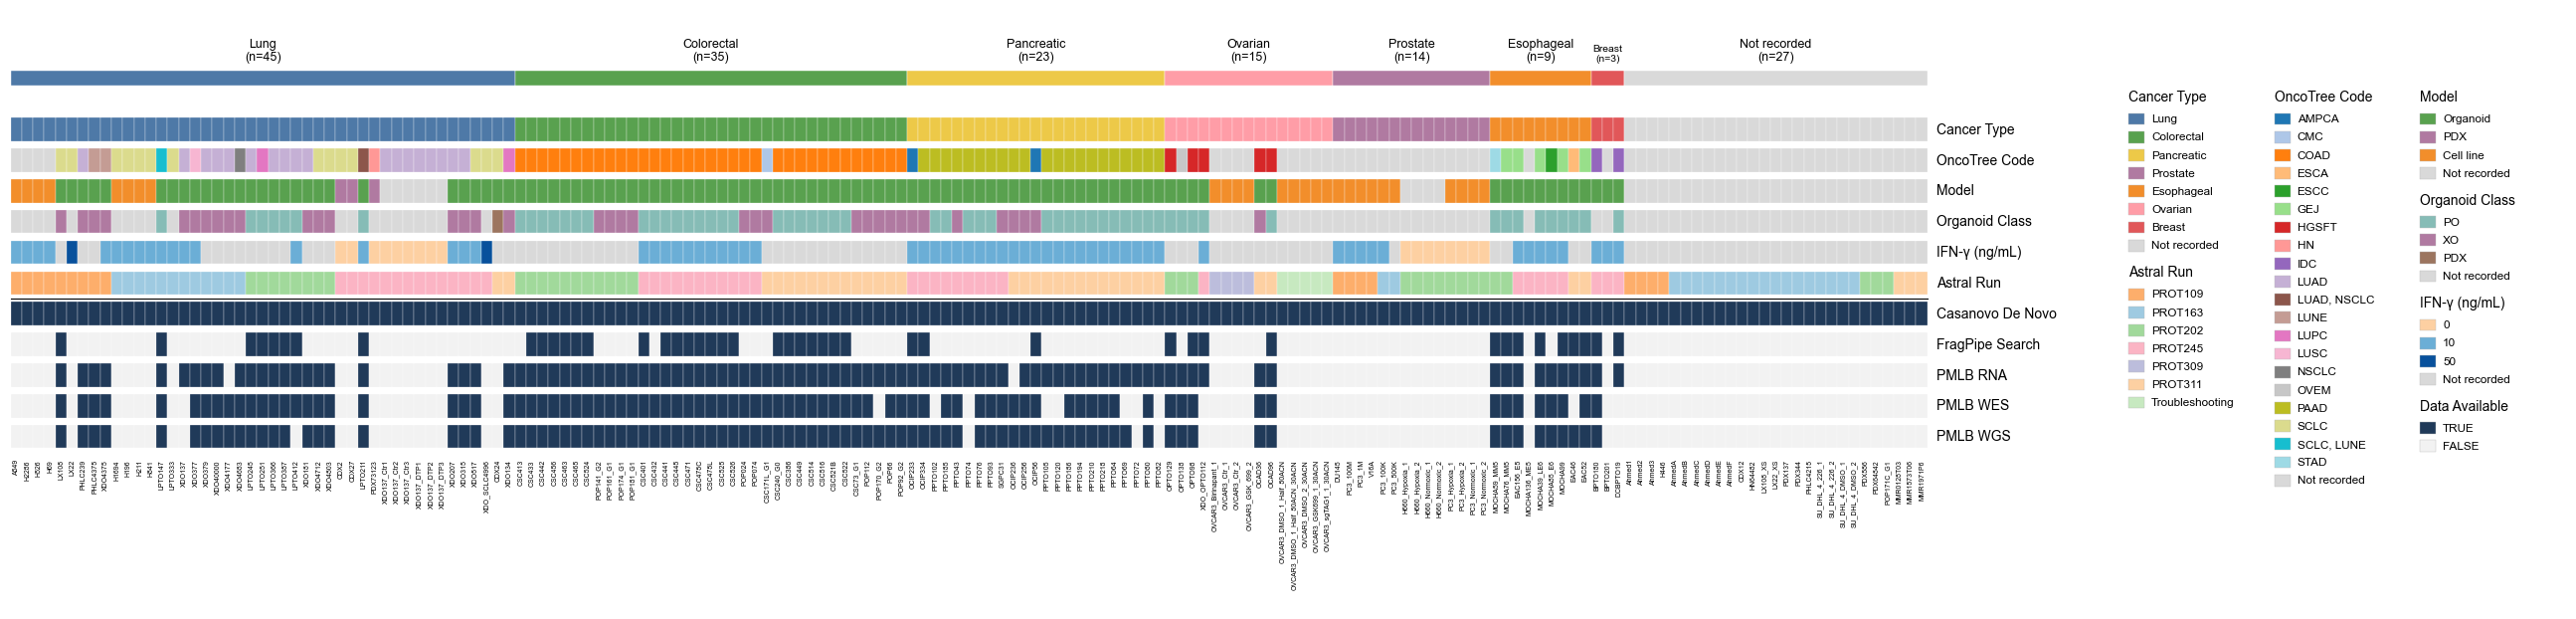

In [4]:
TAB20 = [mpl.colors.to_hex(c) for c in mpl.colormaps["tab20"].colors]
oncotree_codes = sorted(c for c in samples["oncotree"].unique() if c != "Not recorded")
PALETTES = {
    "cancer_type": CANCER_COLORS,
    "oncotree": {**{c: TAB20[i % len(TAB20)] for i, c in enumerate(oncotree_codes)}, "Not recorded": NOT_RECORDED},
    "model": {"Organoid": "#59A14F", "PDX": "#B07AA1", "Cell line": "#F28E2B", "Not recorded": NOT_RECORDED},
    "sample_class": {"PO": "#86bcb6", "XO": "#B07AA1", "PDX": "#9c755f", "Not recorded": NOT_RECORDED},
    "ifng": {"0": "#fdd0a2", "10": "#6baed6", "50": "#08519c", "Not recorded": NOT_RECORDED},
    "ms_run": dict(zip(run_order, ["#FDAE6B", "#9ecae1", "#a1d99b", "#fbb4c4", "#bcbddc", "#fdd0a2", "#c7e9c0", "#d9d9d9"])),
    "availability": {True: "#203A59", False: "#F2F2F2"},
}

# rows to draw, in order: (display label, dataframe column, palette name)
PLOT_ROWS = [
    ("Cancer Type", "cancer_type", "cancer_type"),
    ("OncoTree Code", "oncotree", "oncotree"),
    ("Model", "model", "model"),
    ("Organoid Class", "sample_class", "sample_class"),
    ("IFN-γ (ng/mL)", "ifng", "ifng"),
    ("Astral Run", "ms_run", "ms_run"),
    ("Casanovo De Novo", "has_casanovo", "availability"),
    ("FragPipe Search", "has_fragpipe", "availability"),
    ("PMLB RNA", "pmlb_rna", "availability"),
    ("PMLB WES", "pmlb_wes", "availability"),
    ("PMLB WGS", "pmlb_wgs", "availability"),
]
N_CATEGORY_ROWS = 6  # rows before the TRUE/FALSE availability rows
LEGEND_COLUMNS = [[0, 5], [1], [2, 3, 4, "avail"]]  # legend sections per legend column
LEGEND_COLUMN_WIDTH = 13

ROW_GAP = 0.34
BAR_HEIGHT = 0.26
LEGEND_X_OFFSET = 18
FIGSIZE = (26, 6.4)  # for all samples; the width scales with the number of columns

def draw_sample_overview(table, path, rotate_group_labels=False):
    """one column per sample in table (ordered and indexed 0..n-1), metadata rows above the line, data availability below"""
    n_samples = len(table)
    width = FIGSIZE[0] * (n_samples + LEGEND_X_OFFSET + LEGEND_COLUMN_WIDTH * len(LEGEND_COLUMNS)) / (len(samples) + LEGEND_X_OFFSET + LEGEND_COLUMN_WIDTH * len(LEGEND_COLUMNS))
    fig, ax = plt.subplots(figsize=(width, FIGSIZE[1]))
    legend_x = n_samples + LEGEND_X_OFFSET
    row_label_x = n_samples + 0.8
    max_y = len(PLOT_ROWS) * ROW_GAP

    ax.set_xlim(-0.05, legend_x + LEGEND_COLUMN_WIDTH * len(LEGEND_COLUMNS))
    ax.set_ylim(-1.6 if rotate_group_labels else -1.2, max_y + 1.7)
    ax.invert_yaxis()
    ax.axis("off")

    # top group strip with counts
    for cancer, group in table.groupby("cancer_type", sort=False):
        start = group.index.min()
        width = group.index.max() - start + 1
        ax.add_patch(Rectangle((start, -0.52), width, 0.16, facecolor=CANCER_COLORS.get(cancer, NOT_RECORDED), edgecolor="white", linewidth=0.3))
        label = cancer.replace(" ", "\n") if width < 15 else cancer  # wrap names over narrow groups so they don't overlap
        if rotate_group_labels:  # all labels at one angle, so narrow groups don't collide
            ax.text(start + width / 2, -0.60, f"{cancer} (n={width})", ha="left", va="bottom", rotation=35, rotation_mode="anchor", fontsize=9)
        else:
            ax.text(start + width / 2, -0.60, f"{label}\n(n={width})", ha="center", va="bottom", fontsize=9 if width >= 6 else 7.5)

    for row_i, (label, column, palette_name) in enumerate(PLOT_ROWS):
        y = row_i * ROW_GAP
        ax.text(row_label_x, y + BAR_HEIGHT / 2, label, va="center", ha="left", fontsize=10)
        for sample_i, value in enumerate(table[column]):
            color = PALETTES[palette_name].get(value, NOT_RECORDED)
            ax.add_patch(Rectangle((sample_i, y), 1, BAR_HEIGHT, facecolor=color, edgecolor="white", linewidth=0.2))
    ax.plot([0, n_samples], [N_CATEGORY_ROWS * ROW_GAP - 0.04] * 2, color="black", linewidth=0.8)

    for sample_i, name in enumerate(table["sample_name"]):
        ax.text(sample_i + 0.5, max_y + 0.04, name, rotation=90, ha="center", va="top", fontsize=5)

    for col_i, sections in enumerate(LEGEND_COLUMNS):
        x_pos = legend_x + col_i * LEGEND_COLUMN_WIDTH
        legend_y = -0.15
        for section in sections:
            if section == "avail":
                title = "Data Available"
                items = [("TRUE", PALETTES["availability"][True]), ("FALSE", PALETTES["availability"][False])]
            else:
                title, column, palette_name = PLOT_ROWS[section]
                palette = PALETTES[palette_name]
                items = [(value, palette[value]) for value in palette if value in set(table[column])]
            ax.text(x_pos, legend_y, title, ha="left", va="bottom", fontsize=10)
            legend_y += 0.10
            for item_i, (name, color) in enumerate(items):
                y = legend_y + item_i * 0.20
                ax.add_patch(Rectangle((x_pos, y), 1.4, 0.13, facecolor=color, edgecolor="#bdbdbd", linewidth=0.3))
                ax.text(x_pos + 2.0, y + 0.065, str(name), va="center", ha="left", fontsize=8.5)
            legend_y += len(items) * 0.20 + 0.24

    fig.tight_layout()
    save_fig(fig, path)
    plt.show()


draw_sample_overview(samples, OUT_DIR / "sample_overview.png")

## 2. De Novo Sequencing (Casanovo)

Casanovo reports one peptide for every MS/MS spectrum it reads, so its raw output is a sequence for every spectrum, not a list of confident identifications. Two filters are applied:

- **Precursor match.** The predicted peptide's m/z must be within `PRECURSOR_TOL_PPM` of the measured precursor, allowing the +1 isotope peak (Casanovo's own search settings).
- **Score.** Casanovo's peptide score (mean amino-acid confidence, 0-1) must be ≥ `DENOVO_MIN_SCORE`.

A PSM passing both is a **confident de novo PSM**. Casanovo has no FDR estimate. The score distribution is bimodal, with a high-confidence mode starting at about 0.8, and `DENOVO_MIN_SCORE = 0.8` keeps that mode. The canonical proteome is used as a check: the fraction of de novo peptides found exactly (I/L-equivalent) in UniProt rises steadily with score, with no plateau, so any cutoff trades yield for accuracy (see the table under the plot). Some correct de novo peptides are not in UniProt (mutated, novel or spliced), so this fraction is a lower bound on accuracy.

Requiring a precursor match changes little at high scores. Casanovo already penalizes peptides whose mass doesn't fit, so most of the spectra without a precursor match have scores near 0.

**Caveat.** Casanovo 5.2.1 was run with the default Orbitrap model, which was trained mostly on tryptic peptides. HLA ligands are non-tryptic, so its accuracy here is expected to be lower than on tryptic data.

The first run parses every mzTab into `cache/casanovo_psms.parquet` (one row per spectrum).

In [5]:
PSM_CACHE = CACHE_DIR / "casanovo_psms.parquet"
PSM_COLUMNS = ["sequence", "search_engine_score[1]", "charge", "exp_mass_to_charge", "calc_mass_to_charge"]
ISOTOPE_SPACING = 1.003355


def read_mztab_psms(path):
    """casanovo psm table: peptide, score, charge, precursor match"""
    with open(path) as handle:
        for n_skip, line in enumerate(handle):
            if line.startswith("PSH"):
                break
    psms = pd.read_csv(path, sep="\t", skiprows=n_skip, usecols=PSM_COLUMNS)
    error = psms["exp_mass_to_charge"] - psms["calc_mass_to_charge"]
    isotope = ISOTOPE_SPACING / psms["charge"]
    ppm = np.minimum(error.abs(), (error - isotope).abs()) / psms["calc_mass_to_charge"] * 1e6
    return pd.DataFrame({
        "peptide": psms["sequence"].str.replace(r"[^A-Z]", "", regex=True),
        "score": psms["search_engine_score[1]"].astype("float32"),
        "charge": psms["charge"].astype("int8"),
        "precursor_ok": ppm.le(PRECURSOR_TOL_PPM).values,
    })


if PSM_CACHE.exists():
    psms = pd.read_parquet(PSM_CACHE)
else:
    parts = []
    for i, (alias, path) in enumerate(casanovo_files.items()):
        part = read_mztab_psms(path)
        part.insert(0, "alias", alias)
        parts.append(part)
        if (i + 1) % 20 == 0:
            print(f"parsed {i + 1}/{len(casanovo_files)}")
    psms = pd.concat(parts, ignore_index=True)
    del parts
    psms["alias"] = psms["alias"].astype("category")
    psms["peptide"] = psms["peptide"].astype("category")
    psms.to_parquet(PSM_CACHE, index=False)

# per distinct de novo peptide: in the canonical proteome (i/l-equivalent)? cached as well.
# peptides over 30 aa are not looked up and count as not in the proteome.
IN_PROTEOME_CACHE = CACHE_DIR / "casanovo_peptides_in_proteome.parquet"
categories = psms["peptide"].cat.categories
if IN_PROTEOME_CACHE.exists():
    in_proteome = pd.read_parquet(IN_PROTEOME_CACHE).set_index("peptide")["in_proteome"].reindex(categories).fillna(False).values
else:
    in_proteome = proteome.contains(categories)
    pd.DataFrame({"peptide": categories, "in_proteome": in_proteome}).to_parquet(IN_PROTEOME_CACHE, index=False)
codes = psms["peptide"].cat.codes.values
psms["in_proteome"] = in_proteome[codes]
psms["length"] = categories.str.len().values[codes].astype("int16")
# i/l-folded peptide, for comparisons with fragpipe
il_codes, il_categories = pd.factorize(categories.str.replace("I", "L", regex=False))
psms["peptide_il"] = pd.Categorical.from_codes(il_codes[codes], categories=il_categories)
psms["confident"] = psms["precursor_ok"] & psms["score"].ge(DENOVO_MIN_SCORE)
print(f"{len(psms):,} de novo PSMs from {psms['alias'].nunique()} runs; {psms['confident'].sum():,} confident "
      f"({psms['confident'].mean():.1%})")

11,612,332 de novo PSMs from 171 runs; 1,417,881 confident (12.2%)


**Calibration.** PSMs from all runs pooled, in score bins of 0.05.

- **Left:** PSMs per score bin, split by precursor match.
- **Middle:** fraction of PSMs whose peptide is in the canonical proteome, by score bin. The dashed line marks `DENOVO_MIN_SCORE`.
- **Right:** length of confident de novo peptides. HLA-I ligands are mostly 8-11 residues long.

/var/folders/y_/n7t8whz54_q5s7xfy2s01ypw0000gn/T/ipykernel_58991/799692248.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  calibration = psms.groupby(["score_bin", "precursor_ok"]).agg(n=("in_proteome", "size"), in_proteome=("in_proteome", "mean")).reset_index()


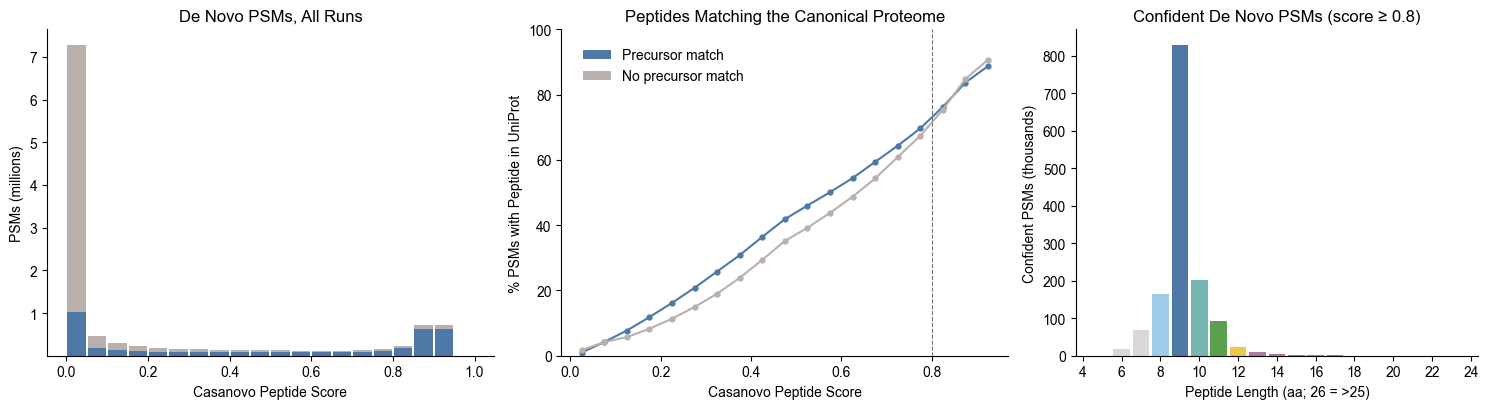

,score cutoff,confident PSMs,% in UniProt
0,0.5,1986330,77.3
1,0.6,1812163,80.1
2,0.7,1638399,82.6
3,0.8,1417881,84.9
4,0.9,617048,88.7


In [6]:
bins = np.round(np.arange(0, 1.0001, 0.05), 2)
psms["score_bin"] = pd.cut(psms["score"], bins, include_lowest=True, labels=bins[:-1] + 0.025)
calibration = psms.groupby(["score_bin", "precursor_ok"]).agg(n=("in_proteome", "size"), in_proteome=("in_proteome", "mean")).reset_index()
calibration["score_bin"] = calibration["score_bin"].astype(float)
PRECURSOR_COLORS = {True: "#4e79a7", False: "#bab0ac"}
PRECURSOR_LABELS = {True: "Precursor match", False: "No precursor match"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1, 0.9]})
ax = axes[0]
bottom = np.zeros(len(bins) - 1)
for ok in [True, False]:
    sub = calibration.loc[calibration["precursor_ok"].eq(ok)].set_index("score_bin").reindex(bins[:-1] + 0.025)
    ax.bar(sub.index, sub["n"].fillna(0) / 1e6, bottom=bottom, width=0.045, color=PRECURSOR_COLORS[ok], label=PRECURSOR_LABELS[ok])
    bottom += sub["n"].fillna(0).values / 1e6
ax.set_xlabel("Casanovo Peptide Score")
ax.set_ylabel("PSMs (millions)")
ax.set_title("De Novo PSMs, All Runs")

ax = axes[1]
for ok in [True, False]:
    sub = calibration.loc[calibration["precursor_ok"].eq(ok) & calibration["n"].ge(100)]
    ax.plot(sub["score_bin"], sub["in_proteome"] * 100, marker="o", markersize=3.5, color=PRECURSOR_COLORS[ok], label=PRECURSOR_LABELS[ok])
ax.axvline(DENOVO_MIN_SCORE, color="#6b7280", linestyle="--", linewidth=0.8)
ax.set_xlabel("Casanovo Peptide Score")
ax.set_ylabel("% PSMs with Peptide in UniProt")
ax.set_ylim(0, 100)
ax.set_title("Peptides Matching the Canonical Proteome")
left_legend(ax, [Patch(facecolor=PRECURSOR_COLORS[k], label=v) for k, v in PRECURSOR_LABELS.items()], "", (0.02, 0.98))

ax = axes[2]
confident_lengths = psms.loc[psms["confident"], "length"].clip(upper=26).value_counts().sort_index()
ax.bar(confident_lengths.index, confident_lengths.values / 1e3, color=[LENGTH_COLORS[length_bin(n)] for n in confident_lengths.index], width=0.85)
ax.set_xlabel("Peptide Length (aa; 26 = >25)")
ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(2))
ax.set_ylabel("Confident PSMs (thousands)")
ax.set_title(f"Confident De Novo PSMs (score ≥ {DENOVO_MIN_SCORE})")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, OUT_DIR / "denovo_score_calibration.png")
plt.show()

above = psms.loc[psms["precursor_ok"]]
cal_table = pd.DataFrame({
    "score cutoff": [0.5, 0.6, 0.7, 0.8, 0.9],
    "confident PSMs": [int(above["score"].ge(c).sum()) for c in [0.5, 0.6, 0.7, 0.8, 0.9]],
    "% in UniProt": [round(above.loc[above["score"].ge(c), "in_proteome"].mean() * 100, 1) for c in [0.5, 0.6, 0.7, 0.8, 0.9]],
})
cal_table

### De novo peptides per sample

- **Top:** MS/MS spectra sequenced per run (light), and the confident de novo PSMs among them (dark).
- **Bottom:** unique confident de novo peptides per run, split by length. The black dots (right axis) are the percentage of those peptides found in the canonical proteome.

The strip under each panel is the cancer type, using the colors of the sample overview.

/var/folders/y_/n7t8whz54_q5s7xfy2s01ypw0000gn/T/ipykernel_58991/532908338.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  "spectra": psms.groupby("alias").size(),
/var/folders/y_/n7t8whz54_q5s7xfy2s01ypw0000gn/T/ipykernel_58991/532908338.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  "confident_psms": denovo.groupby("alias").size(),
/var/folders/y_/n7t8whz54_q5s7xfy2s01ypw0000gn/T/ipykernel_58991/532908338.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt

/var/folders/y_/n7t8whz54_q5s7xfy2s01ypw0000gn/T/ipykernel_58991/532908338.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per_run["pct_in_proteome"] = unique_denovo.groupby("alias")["in_proteome"].mean().reindex(per_run.index) * 100
/var/folders/y_/n7t8whz54_q5s7xfy2s01ypw0000gn/T/ipykernel_58991/532908338.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per_run["pct_hla_i_length"] = unique_denovo.assign(hla=unique_denovo["length"].isin(HLA_I_LENGTHS)).groupby("alias")["hla"].mean().reindex(per_run.index) * 100


/var/folders/y_/n7t8whz54_q5s7xfy2s01ypw0000gn/T/ipykernel_58991/532908338.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unique_denovo.assign(bin=unique_denovo["length"].map(length_bin)).groupby(["bin", "alias"]).size().unstack(fill_value=0)


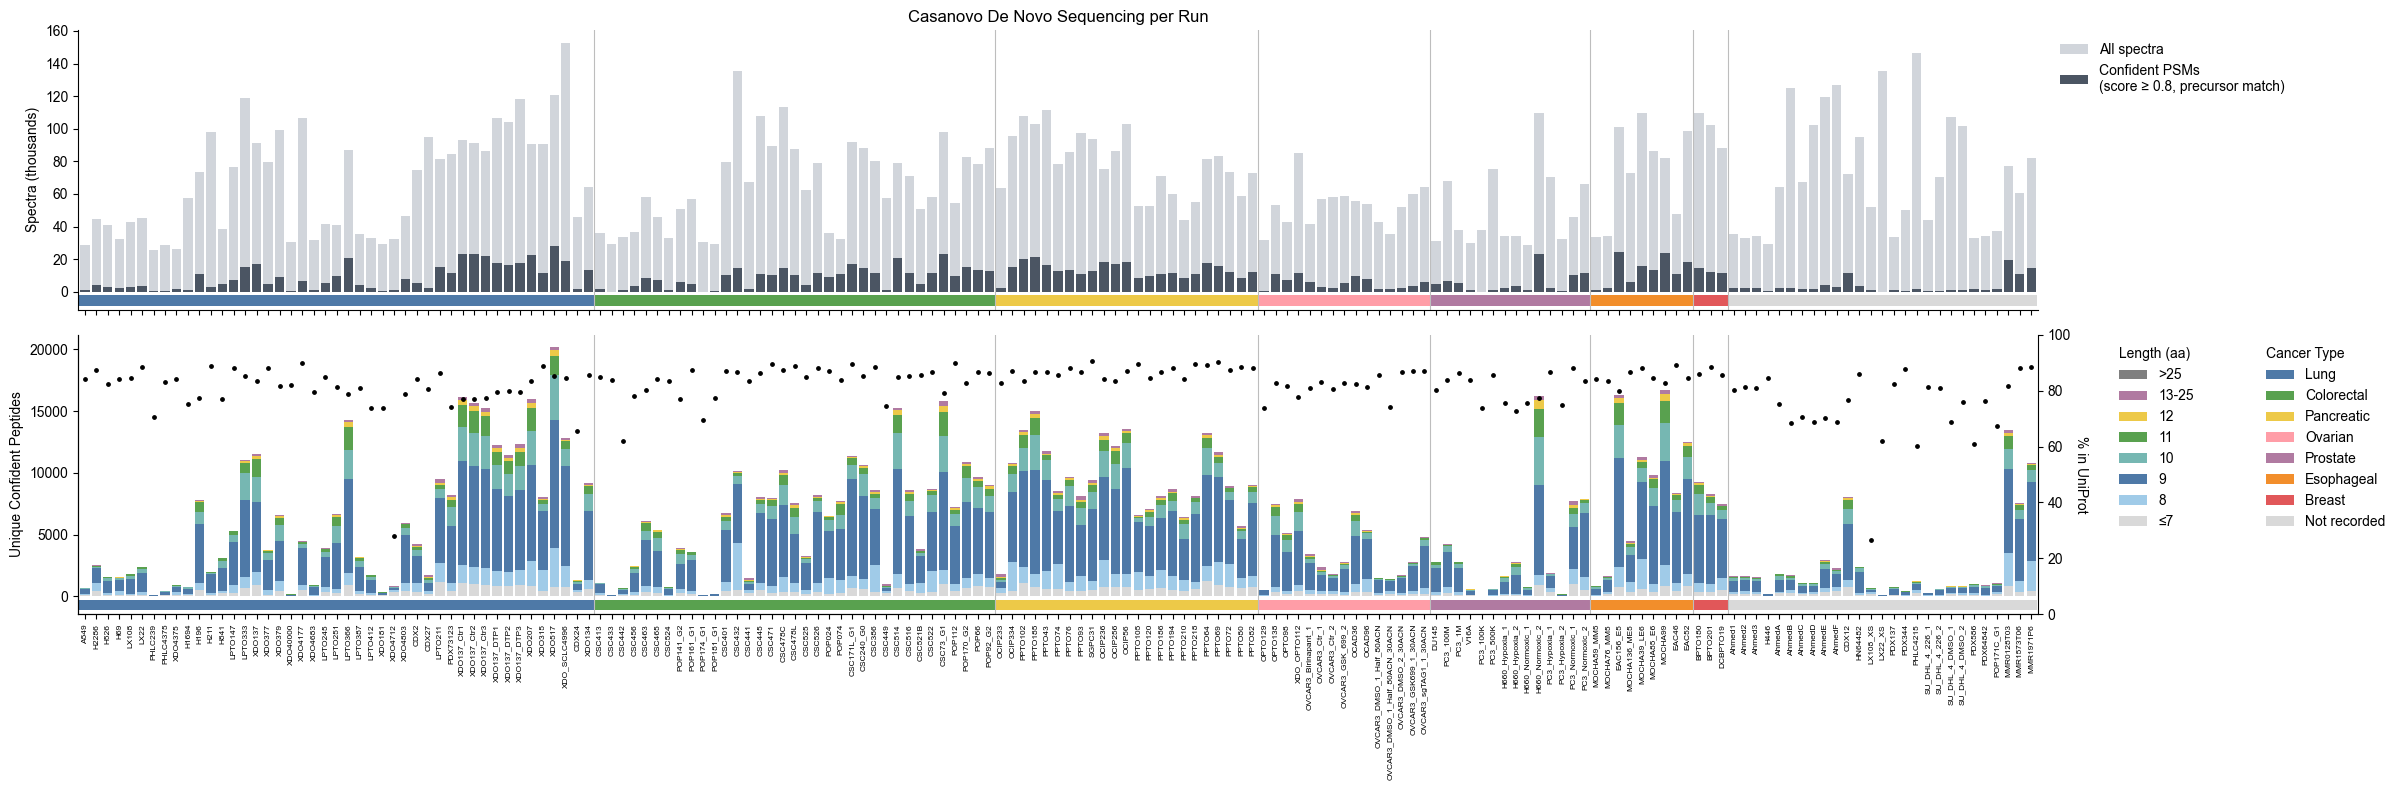

,spectra,confident_psms,confident_peptides,pct_in_proteome,pct_hla_i_length
count,171.0,171.0,171.0,171.0,171.0
mean,67908.4,8291.7,5880.4,81.4,88.6
std,29456.4,6880.0,4842.7,8.7,7.4
min,25906.0,74.0,61.0,26.6,56.7
25%,41247.5,2075.5,1550.0,78.8,86.6
50%,64218.0,7152.0,5159.0,83.7,91.5
75%,89070.0,12701.5,9038.0,86.7,93.2
max,152763.0,27798.0,20165.0,90.5,96.7


In [7]:
denovo = psms.loc[psms["confident"]]
per_run = pd.DataFrame({
    "spectra": psms.groupby("alias").size(),
    "confident_psms": denovo.groupby("alias").size(),
    "confident_peptides": denovo.groupby("alias")["peptide"].nunique(),
}).reindex(samples["alias"]).fillna(0).astype(int)
unique_denovo = denovo.drop_duplicates(["alias", "peptide"])
per_run["pct_in_proteome"] = unique_denovo.groupby("alias")["in_proteome"].mean().reindex(per_run.index) * 100
per_run["pct_hla_i_length"] = unique_denovo.assign(hla=unique_denovo["length"].isin(HLA_I_LENGTHS)).groupby("alias")["hla"].mean().reindex(per_run.index) * 100
samples = samples.drop(columns=[c for c in per_run.columns if c in samples.columns]).merge(per_run, left_on="alias", right_index=True, how="left")

denovo_length_counts = (
    unique_denovo.assign(bin=unique_denovo["length"].map(length_bin)).groupby(["bin", "alias"]).size().unstack(fill_value=0)
    .reindex(index=list(LENGTH_COLORS), columns=samples["alias"]).fillna(0)
)

fig, axes = plt.subplots(2, 1, figsize=(24, 8), sharex=True)
x = np.arange(len(samples))
ax = axes[0]
ax.bar(x, samples["spectra"] / 1e3, color=LIGHT_BAR_COLOR, width=0.82, label="All spectra")
ax.bar(x, samples["confident_psms"] / 1e3, color=BAR_COLOR, width=0.82, label="Confident PSMs")
ax.set_ylabel("Spectra (thousands)")
ax.set_title("Casanovo De Novo Sequencing per Run")
left_legend(ax, [Patch(facecolor=LIGHT_BAR_COLOR, label="All spectra"), Patch(facecolor=BAR_COLOR, label=f"Confident PSMs\n(score ≥ {DENOVO_MIN_SCORE}, precursor match)")], "", (1.005, 1))

ax = axes[1]
stacked_bars(ax, denovo_length_counts, LENGTH_COLORS, x=x)
ax.set_ylabel("Unique Confident Peptides")
ax2 = ax.twinx()
ax2.scatter(x, samples["pct_in_proteome"], s=6, color="black", zorder=3)
ax2.set_ylim(0, 100)
ax2.set_ylabel("% in UniProt", rotation=270, labelpad=12)
ax2.spines[["top"]].set_visible(False)
left_legend(ax, [Patch(facecolor=c, label=l) for l, c in list(LENGTH_COLORS.items())[::-1]], "Length (aa)", (1.035, 1))
left_legend(ax, [Patch(facecolor=CANCER_COLORS[o], label=o) for o in cancer_order], "Cancer Type", (1.11, 1))

for ax in axes:
    bottom_strip(ax, samples["cancer_type"], CANCER_COLORS)
    group_dividers(ax, samples["cancer_type"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(-0.6, len(samples) - 0.4)
axes[1].set_xticks(x)
axes[1].set_xticklabels(samples["sample_name"], rotation=90, fontsize=6)
fig.tight_layout()
save_fig(fig, OUT_DIR / "denovo_peptides_per_sample.png")
plt.show()

samples[["sample_name", "ms_run", "cancer_type", "spectra", "confident_psms", "confident_peptides", "pct_in_proteome", "pct_hla_i_length"]].describe().round(1)

## 3. Sample-Specific Search (FragPipe)

Each sample was searched against its own database: the canonical proteome, FragPipe's common contaminants, and that sample's mutated protein contexts (`MUT_`) and novel ORFs (`NOV_`). `peptide.tsv` is already filtered at 1% peptide FDR.

**Detection.** A peptide is counted in a sample when it appears in that sample's `peptide.tsv`. The `Intensity` column is 0 throughout (no MS1 quantification was run), so spectral counts are the only abundance measure.

In [8]:
PEPTIDE_COLUMNS = ["Peptide", "Peptide Length", "Probability", "Spectral Count", "Assigned Modifications", "Protein", "Gene", "Protein Description", "Mapped Genes", "Mapped Proteins"]
fp_samples = samples.loc[samples["has_fragpipe"]].reset_index(drop=True)

fp_parts, protein_counts = [], {}
for alias in fp_samples["alias"]:
    part = pd.read_csv(fragpipe_files[alias], sep="\t", usecols=PEPTIDE_COLUMNS)
    part.insert(0, "alias", alias)
    fp_parts.append(part)
    proteins = pd.read_csv(FRAGPIPE_DIR / f"{alias}.protein.tsv", sep="\t", usecols=["Protein"])
    protein_counts[alias] = len(proteins)
fp = pd.concat(fp_parts, ignore_index=True)
fp.columns = ["alias", "peptide", "length", "probability", "spectral_count", "modifications", "protein", "gene", "protein_description", "mapped_genes", "mapped_proteins"]
fp["sample_name"] = fp["alias"].map(fp_samples.set_index("alias")["sample_name"])

fp_samples["fragpipe_peptides"] = fp_samples["alias"].map(fp.groupby("alias").size())
fp_samples["fragpipe_proteins"] = fp_samples["alias"].map(protein_counts)
fp_samples["fragpipe_psms"] = fp_samples["alias"].map(fp.groupby("alias")["spectral_count"].sum())
print(f"{len(fp_samples)} samples, {len(fp):,} sample-peptide identifications, {fp['peptide'].nunique():,} unique peptides")
fp_samples[["fragpipe_peptides", "fragpipe_proteins", "fragpipe_psms"]].describe().round(0)

45 samples, 642,992 sample-peptide identifications, 270,598 unique peptides


,fragpipe_peptides,fragpipe_proteins,fragpipe_psms
count,45.0,45.0,45.0
mean,14289.0,5173.0,21650.0
std,8381.0,2358.0,12978.0
min,340.0,170.0,434.0
25%,6558.0,3379.0,10041.0
50%,15872.0,5965.0,23609.0
75%,21133.0,7131.0,32189.0
max,28611.0,8158.0,41575.0


- **Left:** unique peptides per sample. The numbers on the bars are the peptide counts.
- **Right:** the same peptides split by length.

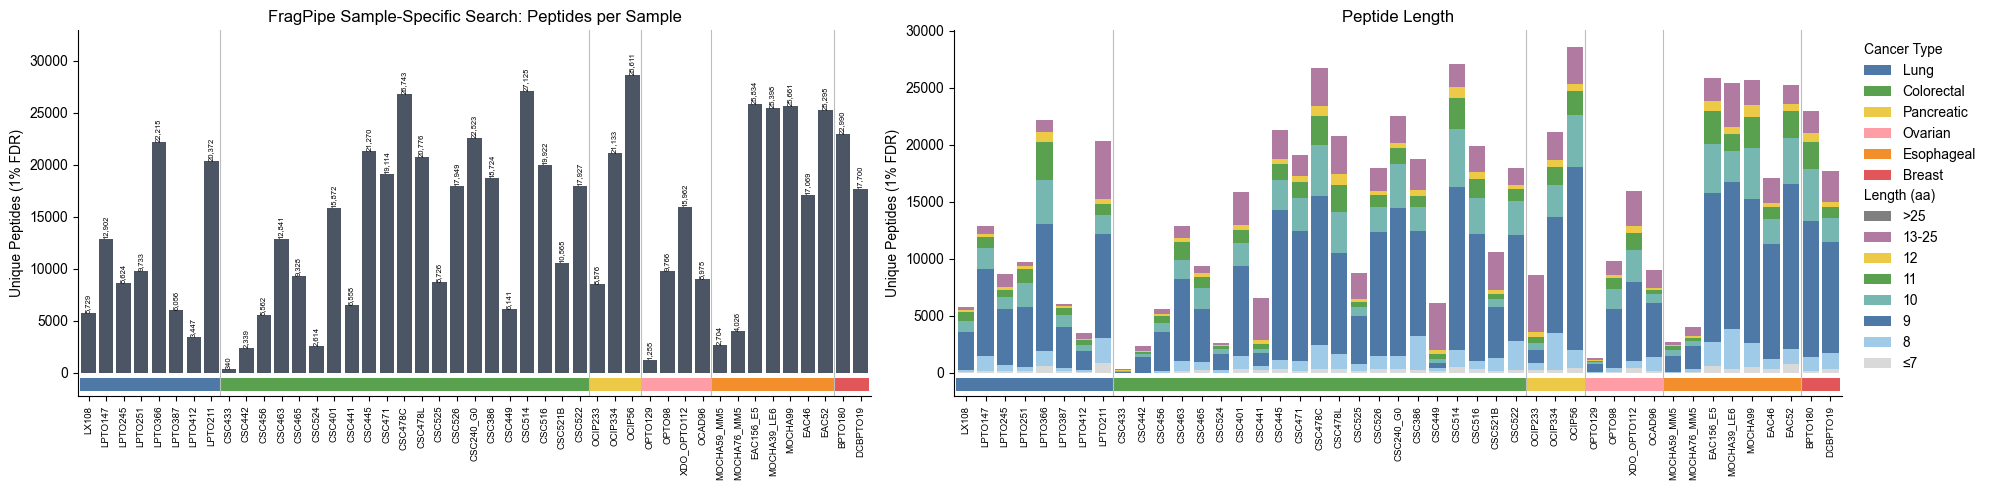

In [9]:
fp_length_counts = (
    fp.assign(bin=fp["length"].map(length_bin)).groupby(["bin", "alias"]).size().unstack(fill_value=0)
    .reindex(index=list(LENGTH_COLORS), columns=fp_samples["alias"]).fillna(0)
)
fig, axes = plt.subplots(1, 2, figsize=(20, 5), gridspec_kw={"width_ratios": [1, 1.12]})
x = np.arange(len(fp_samples))
ax = axes[0]
ax.bar(x, fp_samples["fragpipe_peptides"], color=BAR_COLOR, width=0.82)
for i, v in enumerate(fp_samples["fragpipe_peptides"]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=5.5, rotation=90)
ax.set_ylim(0, fp_samples["fragpipe_peptides"].max() * 1.15)
ax.set_title("FragPipe Sample-Specific Search: Peptides per Sample")
ax = axes[1]
stacked_bars(ax, fp_length_counts, LENGTH_COLORS, x=x)
ax.set_title("Peptide Length")
for ax in axes:
    ax.set_ylabel("Unique Peptides (1% FDR)")
    bottom_strip(ax, fp_samples["cancer_type"], CANCER_COLORS)
    group_dividers(ax, fp_samples["cancer_type"])
    ax.set_xticks(x)
    ax.set_xticklabels(fp_samples["sample_name"], rotation=90, fontsize=7)
    ax.set_xlim(-0.6, len(fp_samples) - 0.4)
    ax.spines[["top", "right"]].set_visible(False)
left_legend(axes[1], [Patch(facecolor=CANCER_COLORS[o], label=o) for o in cancer_order if o in set(fp_samples["cancer_type"])], "Cancer Type", (1.01, 1))
left_legend(axes[1], [Patch(facecolor=c, label=l) for l, c in list(LENGTH_COLORS.items())[::-1]], "Length (aa)", (1.01, 0.6))
fig.tight_layout()
save_fig(fig, OUT_DIR / "fragpipe_peptides_per_sample.png")
plt.show()

## 4. Canonical, Mutated and Novel ORF Peptides

Each peptide is classified from every protein it maps to (`Protein` plus `Mapped Proteins`). The first class that applies wins:

1. **Canonical:** maps to a human UniProt protein (`sp|..._HUMAN`).
2. **Contaminant:** maps only to non-human UniProt proteins (bovine serum albumin, caseins, trypsin and so on, from the culture medium and digestion).
3. **Mutated:** maps to a mutated protein context (`tr|MUT_...`) and no canonical protein, so the peptide carries the mutation.
4. **Novel ORF:** maps only to novel ORFs (`tr|NOV_...`), translated from unannotated transcripts (StringTie assembly). These include alternative splicing junctions, unannotated exons, and ORFs in non-coding or intronic regions.

**I/L check.** FragPipe maps peptide sequences to proteins exactly, so a peptide written with L can miss a canonical protein that has I there, even though the two can't be told apart by mass. Mutated and novel peptides that match the canonical proteome once I and L are treated as the same are moved to **Canonical**.

In [10]:
def classify(accessions):
    accessions = [a.strip() for a in accessions if a.strip()]
    if any(a.startswith("sp|") and a.endswith("_HUMAN") for a in accessions):
        return "Canonical"
    if all(a.startswith("sp|") for a in accessions):
        return "Contaminant"
    if any("|MUT_" in a for a in accessions):
        return "Mutated"
    return "Novel ORF"


fp["accessions"] = (fp["protein"] + "," + fp["mapped_proteins"].fillna("")).str.split(",")
fp["fragpipe_class"] = fp["accessions"].map(classify)
noncanonical = pd.Series(fp.loc[fp["fragpipe_class"].isin(["Mutated", "Novel ORF"]), "peptide"].unique())
il_canonical = set(noncanonical[proteome.contains(noncanonical)])
fp["il_canonical"] = fp["peptide"].isin(il_canonical) & fp["fragpipe_class"].isin(["Mutated", "Novel ORF"])
fp["class"] = np.where(fp["il_canonical"], "Canonical", fp["fragpipe_class"])

print(f"{fp.loc[fp['il_canonical'], 'peptide'].nunique()} mutated/novel peptides moved to Canonical by the I/L check")
class_summary = pd.DataFrame({
    "FragPipe mapping (unique peptides)": fp.groupby("fragpipe_class")["peptide"].nunique(),
    "after I/L check (unique peptides)": fp.groupby("class")["peptide"].nunique(),
    "after I/L check (sample-peptide pairs)": fp.groupby("class").size(),
}).reindex(CLASS_ORDER).fillna(0).astype(int)
class_summary

1 mutated/novel peptides moved to Canonical by the I/L check


,FragPipe mapping (unique peptides),after I/L check (unique peptides),after I/L check (sample-peptide pairs)
Canonical,268830,268831,639669
Mutated,102,102,112
Novel ORF,1256,1255,1613
Contaminant,411,411,1598


**Novel ORF peptides that also map to a canonical protein.** Many novel ORFs are isoforms of known genes, so a peptide can match a novel ORF and a UniProt protein at the same time. FragPipe puts one of them in `Protein` and the rest in `Mapped Proteins`. Which one goes in `Protein` depends on the search database (entry order and headers), not on the peptide, so counting novel ORF peptides from `Protein` alone gives arbitrary numbers. These peptides are classed as **Canonical** here.

For example, an earlier LX108 search (`collaborators/olivia-sclc/data/LX108_combined_peptide.tsv`) had 265 peptides with a novel ORF in `Protein`, but 240 of them also map to a UniProt protein. Only 25 map to novel ORFs alone, and 21 after the I/L check. This search usually lists the UniProt protein first, so `Protein` alone overcounts only slightly (1,743 vs 1,613 sample-peptide pairs over all samples), and for LX108 it gives 12, the same as the full rule.

The table splits every peptide that maps to at least one novel ORF (`tr|NOV_...`) by what else it maps to. `novel ORF in Protein` is the count you would get from the `Protein` column alone.

In [11]:
fp["maps_novel"] = fp["accessions"].map(lambda accs: any("|NOV_" in a for a in accs))
novel_mapping = fp.loc[fp["maps_novel"]].assign(
    mapping=lambda d: np.select(
        [d["fragpipe_class"].eq("Canonical"), d["class"].eq("Canonical"), d["class"].eq("Mutated")],
        ["novel ORF + canonical", "novel ORF + canonical (I/L)", "novel ORF + mutated"],
        "novel ORF only",
    ),
    protein_novel=lambda d: d["protein"].str.contains("|NOV_", regex=False),
)
MAPPING_ORDER = ["novel ORF only", "novel ORF + canonical (I/L)", "novel ORF + canonical", "novel ORF + mutated"]
novel_mapping_per_sample = (
    novel_mapping.groupby(["alias", "mapping"]).size().unstack(fill_value=0)
    .reindex(index=fp_samples["alias"], columns=MAPPING_ORDER).fillna(0).astype(int)
    .assign(**{"maps to a novel ORF": lambda d: d.sum(axis=1)})
    .join(novel_mapping.groupby("alias")["protein_novel"].sum().rename("novel ORF in Protein"))
    .fillna(0).astype(int)
    .set_axis(fp_samples["sample_name"])
)
novel_mapping_per_sample.to_csv(OUT_DIR / "novel_orf_mapping_per_sample.csv")
novel_mapping_per_sample.loc["All samples (sample-peptide pairs)"] = novel_mapping_per_sample.sum()
novel_mapping_per_sample

,novel ORF only,novel ORF + canonical (I/L),novel ORF + canonical,novel ORF + mutated,maps to a novel ORF,novel ORF in Protein
sample_name,,,,,,
LX108,12,0,362,0,374,12
LPTO147,24,0,814,0,838,24
LPTO245,13,0,586,0,599,13
LPTO251,28,0,819,0,847,28
LPTO366,81,0,1397,0,1478,90
LPTO387,0,0,0,0,0,0
LPTO412,15,0,246,0,261,16
LPTO211,58,0,1220,0,1278,64
CSC433,1,0,9,0,10,1


- **Top:** peptides per sample by class. Canonical peptides make up almost all of them.
- **Middle and bottom:** mutated and novel ORF peptides on their own scale. The number above each bar is the count.

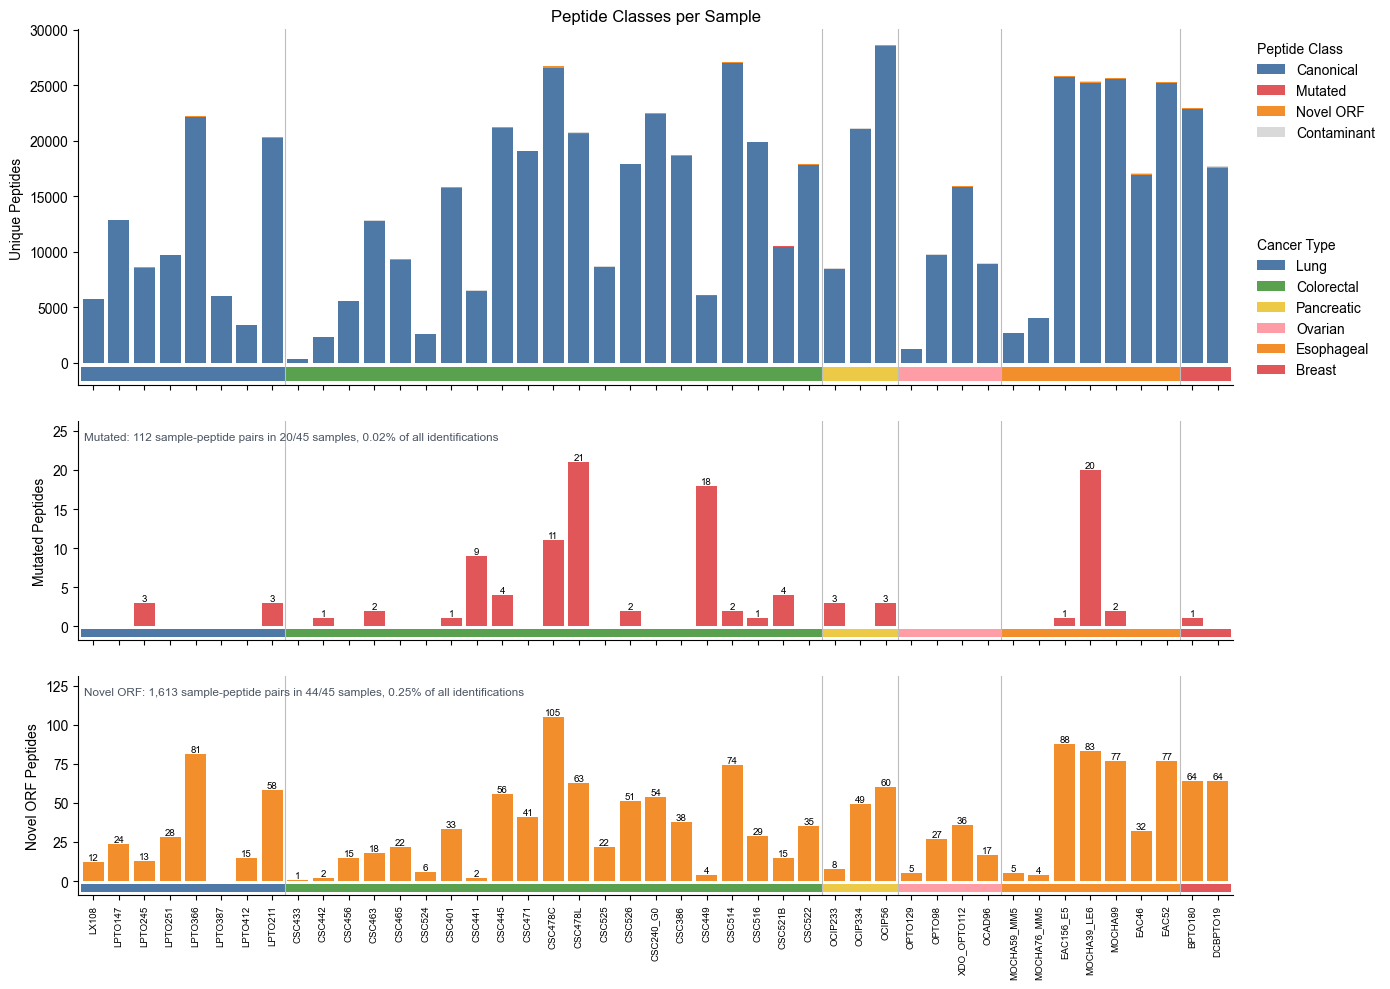

In [12]:
class_counts = fp.groupby(["class", "alias"]).size().unstack(fill_value=0).reindex(index=CLASS_ORDER, columns=fp_samples["alias"]).fillna(0).astype(int)
fp_samples = fp_samples.drop(columns=[c for c in CLASS_ORDER if c in fp_samples.columns]).merge(class_counts.T, left_on="alias", right_index=True)

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [1.3, 0.8, 0.8]})
x = np.arange(len(fp_samples))
stacked_bars(axes[0], class_counts, CLASS_COLORS, x=x)
axes[0].set_ylabel("Unique Peptides")
axes[0].set_title("Peptide Classes per Sample")
for ax, cls in zip(axes[1:], ["Mutated", "Novel ORF"]):
    values = fp_samples[cls].values
    ax.bar(x, values, color=CLASS_COLORS[cls], width=0.82)
    pct = values / fp_samples["fragpipe_peptides"].values * 100
    for i, (v, p) in enumerate(zip(values, pct)):
        if v:
            ax.text(i, v, f"{v}", ha="center", va="bottom", fontsize=7)
    ax.set_ylim(0, max(values.max() * 1.25, 1))
    ax.set_ylabel(f"{cls} Peptides")
    ax.text(0.005, 0.95, f"{cls}: {values.sum():,} sample-peptide pairs in {int((values > 0).sum())}/{len(values)} samples, "
            f"{values.sum() / fp_samples['fragpipe_peptides'].sum() * 100:.2f}% of all identifications", transform=ax.transAxes, va="top", fontsize=8.5, color="#4b5563")
for ax in axes:
    bottom_strip(ax, fp_samples["cancer_type"], CANCER_COLORS)
    group_dividers(ax, fp_samples["cancer_type"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(-0.6, len(fp_samples) - 0.4)
axes[-1].set_xticks(x)
axes[-1].set_xticklabels(fp_samples["sample_name"], rotation=90, fontsize=7)
left_legend(axes[0], [Patch(facecolor=CLASS_COLORS[c], label=c) for c in CLASS_ORDER], "Peptide Class", (1.01, 1))
left_legend(axes[0], [Patch(facecolor=CANCER_COLORS[o], label=o) for o in cancer_order if o in set(fp_samples["cancer_type"])], "Cancer Type", (1.01, 0.45))
fig.tight_layout()
save_fig(fig, OUT_DIR / "peptide_classes_per_sample.png")
plt.show()
class_counts.T.assign(total=class_counts.sum()).set_axis(fp_samples["sample_name"]).to_csv(OUT_DIR / "peptide_classes_per_sample.csv")

**Do the non-canonical peptides look like HLA ligands?** Correct HLA-I ligands have the same length profile whatever protein they come from, peaking sharply at 9 residues. A class made up mostly of false matches would have a flatter length distribution. The right panel shows how many samples each peptide was found in. Novel ORF peptides seen in many unrelated samples are more likely shared, unannotated isoforms than sample-specific events.

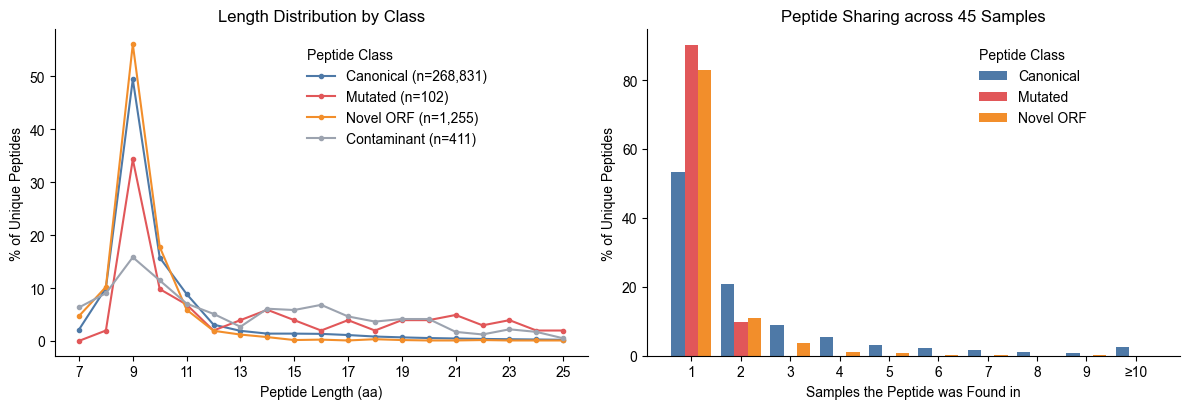

,unique peptides,% 9-mers,% 8-12mers,% 13-25mers
Canonical,268831.0,49.5,87.1,10.7
Mutated,102.0,34.3,54.9,45.1
Novel ORF,1255.0,56.1,91.9,3.4
Contaminant,411.0,15.8,48.4,45.3


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
unique_class = fp.drop_duplicates(["peptide", "class"])
lengths = range(7, 26)
for cls in CLASS_ORDER:
    sub = unique_class.loc[unique_class["class"].eq(cls), "length"]
    dist = sub.value_counts(normalize=True).reindex(lengths, fill_value=0) * 100
    ax.plot(list(lengths), dist.values, marker="o", markersize=3, color=CLASS_COLORS[cls] if cls != "Contaminant" else "#9ca3af", label=f"{cls} (n={len(sub):,})")
ax.set_xlabel("Peptide Length (aa)")
ax.set_ylabel("% of Unique Peptides")
ax.set_title("Length Distribution by Class")
ax.set_xticks(list(range(7, 26, 2)))
left_legend(ax, ax.get_legend_handles_labels()[0], "Peptide Class", (0.45, 0.98))

ax = axes[1]
n_samples_per_peptide = fp.groupby(["class", "peptide"])["alias"].nunique().reset_index(name="n_samples")
max_n = 10
for offset, cls in zip([-0.27, 0, 0.27], ["Canonical", "Mutated", "Novel ORF"]):
    sub = n_samples_per_peptide.loc[n_samples_per_peptide["class"].eq(cls), "n_samples"].clip(upper=max_n)
    dist = sub.value_counts(normalize=True).reindex(range(1, max_n + 1), fill_value=0) * 100
    ax.bar(np.arange(1, max_n + 1) + offset, dist.values, width=0.27, color=CLASS_COLORS[cls], label=cls)
ax.set_xticks(range(1, max_n + 1))
ax.set_xticklabels([str(i) for i in range(1, max_n)] + [f"≥{max_n}"])
ax.set_xlabel("Samples the Peptide was Found in")
ax.set_ylabel("% of Unique Peptides")
ax.set_title(f"Peptide Sharing across {len(fp_samples)} Samples")
left_legend(ax, ax.get_legend_handles_labels()[0], "Peptide Class", (0.6, 0.98))
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, OUT_DIR / "peptide_class_lengths_sharing.png")
plt.show()

pd.DataFrame({
    cls: {
        "unique peptides": len(sub),
        "% 9-mers": round(sub["length"].eq(9).mean() * 100, 1),
        f"% {HLA_I_LENGTHS.start}-{HLA_I_LENGTHS.stop - 1}mers": round(sub["length"].isin(HLA_I_LENGTHS).mean() * 100, 1),
        "% 13-25mers": round(sub["length"].between(13, 25).mean() * 100, 1),
    }
    for cls in CLASS_ORDER for sub in [unique_class.loc[unique_class["class"].eq(cls)]]
}).T

### Mutated peptides

Mutation annotations come from the `MUT_` headers in each sample's `protein.fas` (gene, protein change, mutation type).

**Wild-type check.** For each mutated peptide, `nearest` looks for the same peptide with one substitution in the canonical proteome. For a missense mutation, a hit whose substitution matches the annotated change (for example `p.D88Y`: D in UniProt, Y in the peptide) confirms that the peptide spans the mutated residue and that its wild-type version is a canonical sequence. `matches annotation` is True when the substituted residues agree. Positions can differ because the mutation is numbered on the GENCODE transcript and UniProt may use another isoform.

**De novo support.** The highest Casanovo score for the same peptide (I/L-equivalent, precursor match required) in the same run. This is an independent check, since Casanovo doesn't use the database.

**Things to check before calling a peptide a neoantigen.**
- A peptide whose nearest canonical sequence is a *different* gene, or whose substitution doesn't match the annotation (`matches annotation` False), may be explained by a variant of another protein rather than by the annotated mutation.
- Many mutated peptides are 13-25mers (from histones, keratins and ribosomal proteins), far more often than canonical peptides. These may be HLA-II ligands or non-HLA background. The 8-12mers with de novo support are the strongest HLA-I candidates.
- The search was done with a 1% FDR across all peptides. For a small class such as mutated peptides, a class-specific FDR would be higher.

In [14]:
def parse_mut_headers(path):
    rows = []
    with open(path) as handle:
        for line in handle:
            m = re.match(r">tr\|(MUT_\w+)\|\S+ (\S+) (p\.\S+) (\S+) OS=", line)
            if m:
                rows.append(dict(zip(["mut_id", "mut_gene", "protein_change", "mutation_type"], m.groups())))
    return rows


def parse_nov_headers(path):
    rows = []
    with open(path) as handle:
        for line in handle:
            m = re.match(r">tr\|(NOV_\S+?)\|\S+ Novel ORF \S+ (\S+) strand([+-]) .*GN=(\S+)", line)
            if m:
                rows.append(dict(zip(["nov_id", "orf_type", "strand", "locus"], m.groups())))
    return rows


mut_info = pd.DataFrame([r for a in fp_samples["alias"] for r in parse_mut_headers(FRAGPIPE_DIR / f"{a}.protein.fas")]).drop_duplicates("mut_id").set_index("mut_id")
nov_info = pd.DataFrame([r for a in fp_samples["alias"] for r in parse_nov_headers(FRAGPIPE_DIR / f"{a}.protein.fas")]).drop_duplicates("nov_id").set_index("nov_id")


def accession_ids(accessions, prefix):
    return [a.strip().split("|")[1] for a in accessions if f"|{prefix}" in a]


# best confident-precursor casanovo score per (run, i/l-folded peptide)
denovo_best = (
    psms.loc[psms["precursor_ok"] & psms["score"].ge(DENOVO_KEEP_SCORE), ["alias", "peptide_il", "score"]]
    .groupby(["alias", "peptide_il"], observed=True)["score"].max()
)


def denovo_support(alias, peptide):
    return denovo_best.get((alias, fold_il(peptide)), np.nan)


mutated = fp.loc[fp["class"].eq("Mutated")].copy()
mutated["mut_ids"] = mutated["accessions"].map(lambda a: accession_ids(a, "MUT_"))
mutated = mutated.explode("mut_ids").rename(columns={"mut_ids": "mut_id"}).join(mut_info, on="mut_id")
mutated_long = mutated.drop_duplicates(["alias", "peptide", "mut_gene", "protein_change"])  # one row per peptide and source mutation
mutated = (mutated.groupby(["alias", "sample_name", "peptide"], as_index=False)
           .agg(length=("length", "first"), spectral_count=("spectral_count", "first"), probability=("probability", "first"),
                gene=("mut_gene", lambda s: ";".join(sorted(set(s.dropna())))),
                protein_change=("protein_change", lambda s: ";".join(sorted(set(s.dropna())))),
                mutation_type=("mutation_type", lambda s: ";".join(sorted(set(s.dropna()))))))
nearest = {p: proteome.nearest(p) for p in mutated["peptide"].unique()}
mutated["wt_match"] = mutated["peptide"].map(lambda p: nearest[p][0])
mutated["wt_detail"] = mutated["peptide"].map(lambda p: nearest[p][1])


def matches_annotation(row):
    """substituted residues agree with a missense p.change (I and L folded)"""
    m = re.match(r"p\.([A-Z])(\d+)([A-Z])$", row["protein_change"].split(";")[0])
    d = re.search(r" ([A-Z])(\d+)([A-Z]) \(", row["wt_detail"])
    if not (m and d):
        return np.nan
    return fold_il(m.group(1)) == d.group(1) and fold_il(m.group(3)) == d.group(3)


mutated["matches_annotation"] = mutated.apply(matches_annotation, axis=1)
mutated["denovo_best_score"] = [denovo_support(a, p) for a, p in zip(mutated["alias"], mutated["peptide"])]
mutated = mutated.merge(fp_samples[["alias", "cancer_type"]], on="alias").sort_values(["gene", "protein_change", "sample_name"]).reset_index(drop=True)
mutated.drop(columns="alias").to_csv(OUT_DIR / "mutated_peptides.csv", index=False)
print(f"{len(mutated)} mutated sample-peptide pairs, {mutated['peptide'].nunique()} unique peptides, "
      f"{mutated[['gene', 'protein_change']].drop_duplicates().shape[0]} mutations, {mutated['alias'].nunique()} samples")
print("wild-type check:", mutated.drop_duplicates("peptide")["wt_match"].value_counts().to_dict(),
      "| substitution matches annotation:", mutated.drop_duplicates("peptide")["matches_annotation"].value_counts(dropna=False).to_dict())
mutated.drop(columns=["alias"])

112 mutated sample-peptide pairs, 102 unique peptides, 60 mutations, 20 samples
wild-type check: {'1 substitution': 99, 'none': 3} | substitution matches annotation: {True: 96, False: 3, nan: 3}


,sample_name,peptide,length,spectral_count,probability,gene,protein_change,mutation_type,wt_match,wt_detail,matches_annotation,denovo_best_score,cancer_type
0,MOCHA39_LE6,SPICLRALL,9,2,0.9991,BCL3,p.T219I,missense,1 substitution,EPOP A44L (peptide pos 9),False,NaN,Esophageal
1,LPTO245,KTRDGLFVPK,10,1,0.9944,C1orf174,p.S140F,missense,1 substitution,C1orf174 S140F (peptide pos 7),True,NaN,Lung
2,MOCHA39_LE6,SLLKKPDEV,9,2,0.9978,CAMK2D,p.G326E,missense,1 substitution,CAMK2D G326E (peptide pos 8),True,0.905978,Esophageal
3,MOCHA39_LE6,KLLDYDVHV,9,1,0.9999,CASP2,p.G237D,missense,1 substitution,CASP2 G237D (peptide pos 4),True,NaN,Esophageal
4,MOCHA39_LE6,KLLDYDVHVL,10,2,1.0000,CASP2,p.G237D,missense,1 substitution,CASP2 G237D (peptide pos 4),True,0.899307,Esophageal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,OCIP233,ERINVYYNEATGGKHVPRAVL,21,2,1.0000,TUBB4B,p.Y59H,missense,1 substitution,TUBB4B Y59H (peptide pos 15),True,NaN,Pancreatic
108,MOCHA39_LE6,DLRYKLLL,8,1,0.9935,UBE2C,p.S82L,missense,1 substitution,UBE2C S82L (peptide pos 7),True,0.908998,Esophageal
109,MOCHA39_LE6,LPRKVNKDSIF,11,1,0.9983,USP14,p.L179Cfs*29,frameshift,none,,NaN,NaN,Esophageal
110,CSC445,SMPEAQSAL,9,1,0.9980,ZFAND6,p.V71M,missense,1 substitution,ZFAND6 V71M (peptide pos 2),True,0.908250,Colorectal


Each row is one mutation in one sample, labelled `gene protein change (sample)`. Bar length is the spectral count of the best mutated peptide, colored by mutation type. Marks on the right:

- **WT**: the annotated substitution was found against a canonical wild-type sequence (`matches annotation`).
- **DN**: Casanovo sequenced the same peptide in that run with a confident score (≥ `DENOVO_MIN_SCORE`).

/var/folders/y_/n7t8whz54_q5s7xfy2s01ypw0000gn/T/ipykernel_58991/861598002.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  wt=("matches_annotation", lambda s: bool(s.fillna(False).astype(bool).any())),
/var/folders/y_/n7t8whz54_q5s7xfy2s01ypw0000gn/T/ipykernel_58991/861598002.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  wt=("matches_annotation", lambda s: bool(s.fillna(False).astype(bool).any())),
/var/folders/y_/n7t8whz54_q5s7xfy2s01ypw0000gn/T/ipykernel_58991/861598002.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, 

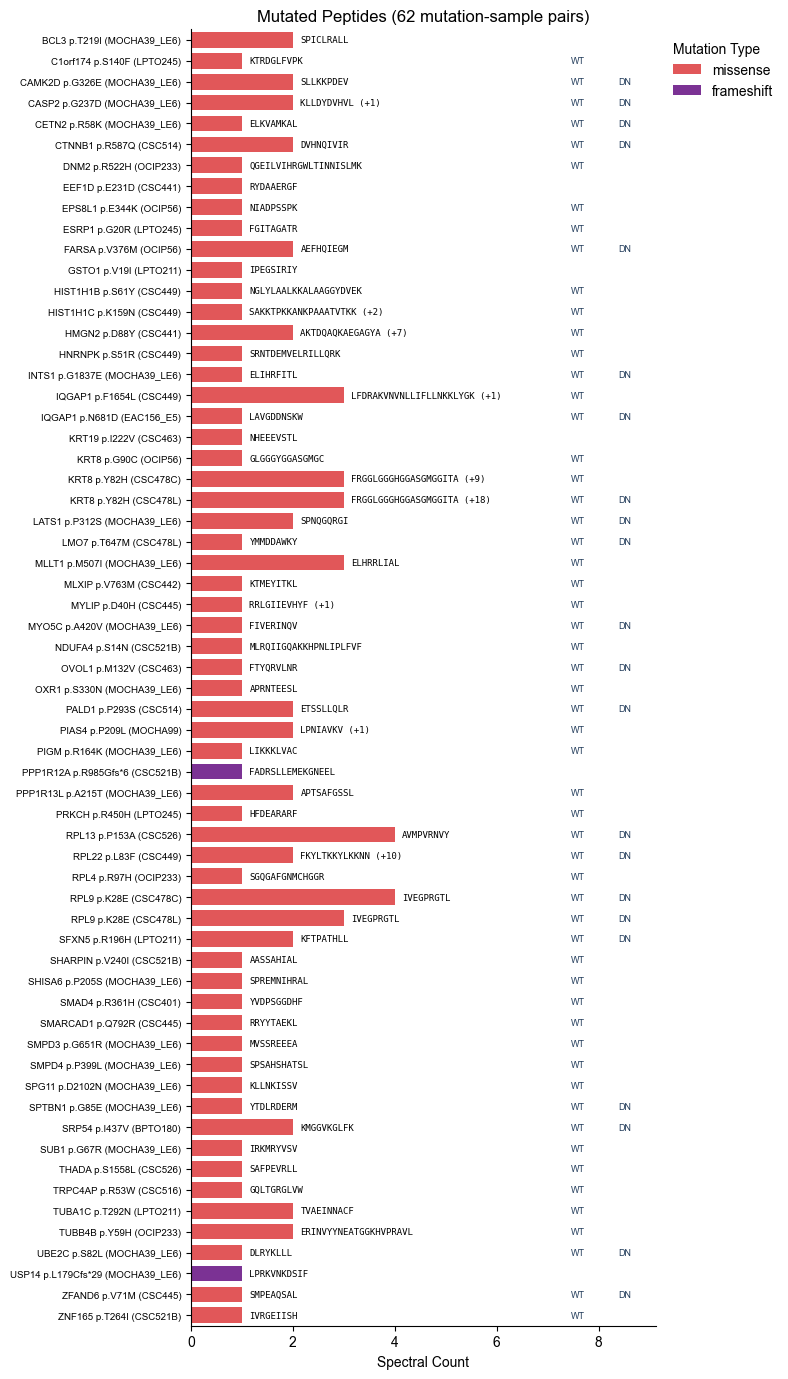

In [15]:
MUTATION_TYPE_COLORS = {"missense": "#e15759", "frameshift": "#7b3294", "inframe_insertion": "#f28e2b", "inframe_deletion": "#edc948", "nonsense": "#4b5563"}
per_mutation = (mutated.sort_values("spectral_count", ascending=False)
                .groupby(["sample_name", "gene", "protein_change"], as_index=False)
                .agg(peptide=("peptide", "first"), spectral_count=("spectral_count", "first"), n_peptides=("peptide", "nunique"),
                     mutation_type=("mutation_type", "first"), cancer_type=("cancer_type", "first"),
                     wt=("matches_annotation", lambda s: bool(s.fillna(False).astype(bool).any())),
                     denovo=("denovo_best_score", lambda s: bool(s.ge(DENOVO_MIN_SCORE).any()))))
per_mutation = per_mutation.sort_values(["gene", "protein_change", "sample_name"]).reset_index(drop=True)
labels = [f"{g} {c} ({s})" for g, c, s in zip(per_mutation["gene"], per_mutation["protein_change"], per_mutation["sample_name"])]

fig, ax = plt.subplots(figsize=(8, 0.2 * len(per_mutation) + 1.5))
y = np.arange(len(per_mutation))
ax.barh(y, per_mutation["spectral_count"], color=[MUTATION_TYPE_COLORS.get(t.split(";")[0], "#9ca3af") for t in per_mutation["mutation_type"]], height=0.75)
for i, row in per_mutation.iterrows():
    ax.text(row["spectral_count"] + 0.15, i, row["peptide"] + (f" (+{row['n_peptides'] - 1})" if row["n_peptides"] > 1 else ""), va="center", fontsize=6.5, family="monospace")
x_mark = per_mutation["spectral_count"].max() * 1.9
for i, row in per_mutation.iterrows():
    ax.text(x_mark, i, "WT" if row["wt"] else "", va="center", ha="center", fontsize=6.5, color="#203A59")
    ax.text(x_mark * 1.12, i, "DN" if row["denovo"] else "", va="center", ha="center", fontsize=6.5, color="#203A59")
ax.set_xlim(0, x_mark * 1.2)
ax.set_ylim(len(per_mutation) - 0.5, -0.5)
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=7)
ax.set_xlabel("Spectral Count")
ax.set_title(f"Mutated Peptides ({len(per_mutation)} mutation-sample pairs)")
ax.spines[["top", "right"]].set_visible(False)
left_legend(ax, [Patch(facecolor=c, label=t) for t, c in MUTATION_TYPE_COLORS.items() if t in set(per_mutation["mutation_type"].str.split(";").str[0])], "Mutation Type", (1.01, 1))
fig.tight_layout()
save_fig(fig, OUT_DIR / "mutated_peptides.png")
plt.show()

### Source mutations

Each mutated peptide comes from a somatic mutation. Here those mutations are looked up in the MAF the search databases were built from (`MAF_PATH`). This checks that the mutation is called in the sample the peptide was found in, and adds its VAF, gnomAD frequency and recurrence.

**Sample to MAF barcode.** `pmlb_organoid_id` is matched to `Tumor_Sample_Barcode` after stripping batch/replicate suffixes (`.r1`, `_pmlb`, ...). Where that fails (for example `CSC0449.TPT`, when the MAF only has `CSC0449.TPO`), another tumor barcode from the same patient is used: the one whose calls best overlap the sample's mutated peptides, then `TPO` > `TXO` > `TPT`. Normal barcodes (`.NPT`, `.NPO`) are never used. `maf_match` records which rule was used.

In [16]:
MAF_COLUMNS = ["Hugo_Symbol", "Tumor_Sample_Barcode", "Variant_Classification", "HGVSp_Short", "t_depth", "t_alt_count", "FILTER", "gnomAD_AF"]
maf = pd.read_csv(MAF_PATH, sep="\t", usecols=MAF_COLUMNS, low_memory=False).rename(columns={
    "Hugo_Symbol": "gene", "Tumor_Sample_Barcode": "raw_barcode", "Variant_Classification": "variant_class", "HGVSp_Short": "protein_change"})
maf["barcode"] = maf["raw_barcode"].str.replace(r"(_pmlb|_novo\d*|\.r\d+|_r\d+)+$", "", regex=True)
maf["vaf"] = maf["t_alt_count"] / maf["t_depth"]
maf["mutation"] = maf["gene"] + " " + maf["protein_change"].fillna("")
# replicate runs of one sample: keep the deepest call of each mutation
maf = maf.sort_values("t_depth", ascending=False).drop_duplicates(["barcode", "mutation"]).reset_index(drop=True)
maf["germline_like"] = maf["gnomAD_AF"].fillna(0).gt(GERMLINE_GNOMAD_AF) | maf["FILTER"].eq("common_variant")
maf_sets = maf.groupby("barcode")["mutation"].agg(set)
tumor_barcodes = [b for b in maf_sets.index if not b.split(".")[-1].startswith("N")]
TYPE_RANK = {"TPO": 0, "TXO": 1, "TPT": 2}

detected_mutations = (mutated_long["mut_gene"] + " " + mutated_long["protein_change"]).groupby(mutated_long["alias"]).agg(set)


def pick_barcode(organoid_id, detected):
    if pd.isna(organoid_id):
        return np.nan, "no PMLB id"
    barcode = re.sub(r"(_pmlb|_novo\d*|\.r\d+|_r\d+)+$", "", organoid_id)
    if barcode in maf_sets.index:
        return barcode, "exact"
    candidates = [b for b in tumor_barcodes if b.split(".")[0] == barcode.split(".")[0]]
    if not candidates:
        return np.nan, "not in MAF"
    best = min(candidates, key=lambda b: (-len(detected & maf_sets[b]), TYPE_RANK.get(b.split(".")[-1][:3], 9), b))
    return best, "same patient"


picked = [pick_barcode(o, detected_mutations.get(a, set())) for o, a in zip(fp_samples["pmlb_organoid_id"], fp_samples["alias"])]
fp_samples["maf_barcode"] = [b for b, _ in picked]
fp_samples["maf_match"] = [m for _, m in picked]
altering = maf.loc[maf["variant_class"].isin(PROTEIN_ALTERING)]
fp_samples["maf_protein_altering"] = fp_samples["maf_barcode"].map(altering.groupby("barcode").size())
fp_samples["maf_driver_mutations"] = fp_samples["maf_barcode"].map(altering.loc[altering["gene"].isin(DRIVER_GENES)].groupby("barcode").size())
fp_samples[["sample_name", "pmlb_organoid_id", "maf_barcode", "maf_match", "maf_protein_altering", "maf_driver_mutations", "Mutated"]].set_index("sample_name")

,pmlb_organoid_id,maf_barcode,maf_match,maf_protein_altering,maf_driver_mutations,Mutated
sample_name,,,,,,
LX108,LX0108.TXO,LX0108.TXO,exact,498.0,2.0,0
LPTO147,LPTO0147.TPO,LPTO0147.TPO,exact,345.0,NaN,0
LPTO245,LPTO0245.TPO,LPTO0245.TPO,exact,392.0,2.0,3
LPTO251,LPTO0251.TPO,LPTO0251.TPO,exact,370.0,NaN,0
LPTO366,LPTO0366.TPO,LPTO0366.TPO,exact,332.0,2.0,0
LPTO387,LPTO0387.TPO,NaN,not in MAF,NaN,NaN,0
LPTO412,LPTO0412.TPO,NaN,not in MAF,NaN,NaN,0
LPTO211,LPTO0221.TPO,LPTO0221.TPO,exact,337.0,3.0,3
CSC433,CSC0433.TPO,CSC0433.TPO,exact,324.0,1.0,0


One row per source mutation and sample. `called_in_sample` is True when the mutation is in that sample's MAF calls; it should be True for every row, since each database was built from its sample's calls. `cohort_samples` counts the MAF tumor samples (all 300+, not only the searched ones) that carry the mutation. `germline_like` flags calls with gnomAD AF > `GERMLINE_GNOMAD_AF` or `FILTER = common_variant`.

In [17]:
source = (mutated_long.assign(mutation=mutated_long["mut_gene"] + " " + mutated_long["protein_change"])
          .merge(mutated[["alias", "peptide", "denovo_best_score"]].drop_duplicates(), on=["alias", "peptide"], how="left")
          .groupby(["alias", "sample_name", "mutation", "mut_gene", "protein_change"], as_index=False)
          .agg(mutation_type=("mutation_type", "first"), n_peptides=("peptide", "nunique"), spectral_count=("spectral_count", "sum"),
               peptides=("peptide", lambda s: ";".join(sorted(set(s)))), denovo_best_score=("denovo_best_score", "max")))
source = source.merge(fp_samples[["alias", "maf_barcode", "cancer_type"]], on="alias", how="left")
calls = maf.set_index(["barcode", "mutation"])[["variant_class", "vaf", "t_depth", "t_alt_count", "gnomAD_AF", "FILTER", "germline_like"]]
source = source.join(calls, on=["maf_barcode", "mutation"])
source["called_in_sample"] = source["variant_class"].notna()
cohort_counts = maf.loc[maf["barcode"].isin(tumor_barcodes)].groupby("mutation")["barcode"].nunique()
source["cohort_samples"] = source["mutation"].map(cohort_counts).fillna(0).astype(int)
searched_barcodes = set(fp_samples["maf_barcode"].dropna())
source["searched_samples_called"] = source["mutation"].map(maf.loc[maf["barcode"].isin(searched_barcodes)].groupby("mutation")["barcode"].nunique()).fillna(0).astype(int)
source = source.sort_values(["spectral_count", "n_peptides"], ascending=False).reset_index(drop=True)
source.drop(columns="alias").to_csv(OUT_DIR / "source_mutations.csv", index=False)
print(f"{len(source)} mutation-sample pairs, {source['mutation'].nunique()} mutations; "
      f"called in the sample's MAF: {source['called_in_sample'].sum()}/{len(source)}; germline-like: {int(source['germline_like'].fillna(False).sum())}")
source[["sample_name", "mutation", "mutation_type", "n_peptides", "spectral_count", "vaf", "t_depth", "gnomAD_AF", "germline_like",
        "cohort_samples", "searched_samples_called", "called_in_sample", "denovo_best_score"]].head(N_TOP_MUTATIONS).round(3)

62 mutation-sample pairs, 60 mutations; called in the sample's MAF: 62/62; germline-like: 6


,sample_name,mutation,mutation_type,n_peptides,spectral_count,vaf,t_depth,gnomAD_AF,germline_like,cohort_samples,searched_samples_called,called_in_sample,denovo_best_score
0,CSC478L,KRT8 p.Y82H,missense,19,27,0.440,25,NaN,True,3,2,True,0.874
1,CSC478C,KRT8 p.Y82H,missense,10,18,0.417,12,NaN,True,3,2,True,NaN
2,CSC449,RPL22 p.L83F,missense,11,12,0.524,21,NaN,False,1,1,True,0.835
3,CSC441,HMGN2 p.D88Y,missense,8,9,0.309,55,NaN,False,1,1,True,NaN
4,CSC449,IQGAP1 p.F1654L,missense,2,5,0.376,101,NaN,False,1,1,True,NaN
5,CSC478C,RPL9 p.K28E,missense,1,4,0.545,22,NaN,False,2,2,True,0.910
6,CSC526,RPL13 p.P153A,missense,1,4,0.510,49,NaN,False,1,1,True,0.922
7,CSC449,HIST1H1C p.K159N,missense,3,3,0.552,29,NaN,False,1,1,True,NaN
8,MOCHA39_LE6,CASP2 p.G237D,missense,2,3,0.456,68,NaN,False,1,1,True,0.899
9,MOCHA99,PIAS4 p.P209L,missense,2,3,1.000,39,NaN,False,1,1,True,NaN


**Top source mutations.** The `N_TOP_MUTATIONS` mutations with the most mutated-peptide spectra, summed over samples.

- **Left:** total spectral count, colored by mutation type. The label is the number of distinct mutated peptides. `†` marks a germline-like call.
- **Right:** for every searched sample that carries one of these mutations, an open gray circle means the mutation is called in the sample's MAF. A filled circle means a mutated peptide was also found, colored by the mutation's VAF in that sample and sized by spectral count. A mutation called in several samples but seen as a peptide in only one usually reflects HLA type: each sample presents a different set of peptides.

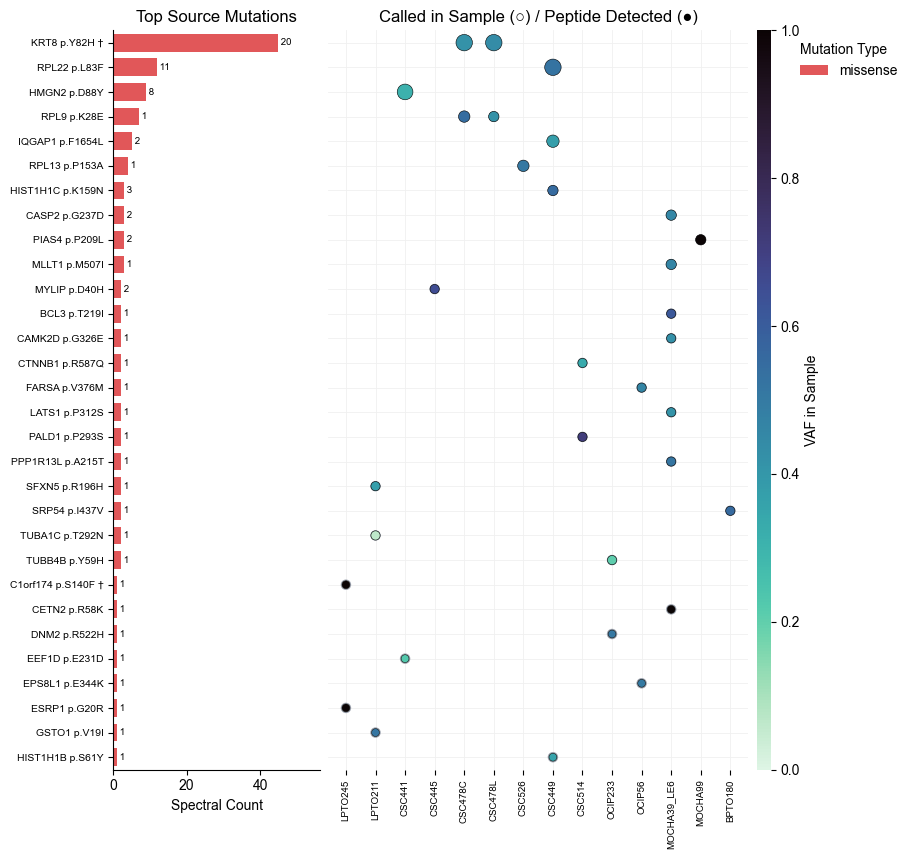

In [18]:
top = (source.groupby("mutation").agg(spectral_count=("spectral_count", "sum"), n_peptides=("peptides", lambda s: len(set(";".join(s).split(";")))),
                                     mutation_type=("mutation_type", "first"), germline_like=("germline_like", lambda s: bool(s.fillna(False).any())))
       .sort_values(["spectral_count", "n_peptides"], ascending=False).head(N_TOP_MUTATIONS))
called = maf.loc[maf["mutation"].isin(top.index) & maf["barcode"].isin(searched_barcodes), ["barcode", "mutation", "vaf"]]
barcode_to_sample = fp_samples.dropna(subset=["maf_barcode"]).drop_duplicates("maf_barcode").set_index("maf_barcode")["sample_name"]
called = called.assign(sample_name=called["barcode"].map(barcode_to_sample))
detected = source.loc[source["mutation"].isin(top.index)]
columns = [s for s in fp_samples["sample_name"] if s in set(called["sample_name"]) | set(detected["sample_name"])]
row_of = {m: i for i, m in enumerate(top.index)}
col_of = {s: j for j, s in enumerate(columns)}

fig = plt.figure(figsize=(4 + 0.32 * len(columns), 0.24 * len(top) + 2.4))
grid = fig.add_gridspec(1, 3, width_ratios=[2.2, 0.32 * len(columns), 0.15], wspace=0.04)
ax_bar = fig.add_subplot(grid[0, 0])
ax_dot = fig.add_subplot(grid[0, 1], sharey=ax_bar)
cax = fig.add_subplot(grid[0, 2])
y = np.arange(len(top))
ax_bar.barh(y, top["spectral_count"], color=[MUTATION_TYPE_COLORS.get(t, "#9ca3af") for t in top["mutation_type"]], height=0.72)
for i, (v, n) in enumerate(zip(top["spectral_count"], top["n_peptides"])):
    ax_bar.text(v, i, f" {n}", va="center", fontsize=7)
ax_bar.set_yticks(y)
ax_bar.set_yticklabels([f"{m}{' †' if g else ''}" for m, g in zip(top.index, top["germline_like"])], fontsize=7.5)
ax_bar.set_ylim(len(top) - 0.5, -0.5)
ax_bar.set_xlim(0, top["spectral_count"].max() * 1.25)
ax_bar.set_xlabel("Spectral Count")
ax_bar.set_title("Top Source Mutations")
ax_bar.spines[["top", "right"]].set_visible(False)

vaf_norm = mpl.colors.Normalize(vmin=0, vmax=1)
vaf_cmap = mpl.colormaps["mako_r"]
ax_dot.scatter([col_of[s] for s in called["sample_name"]], [row_of[m] for m in called["mutation"]], s=45, facecolor="none", edgecolor="#9ca3af", linewidth=0.8)
ax_dot.scatter([col_of[s] for s in detected["sample_name"]], [row_of[m] for m in detected["mutation"]], s=20 + 12 * detected["spectral_count"].clip(upper=10),
               c=vaf_cmap(vaf_norm(detected["vaf"].fillna(0))), edgecolor="black", linewidth=0.4, zorder=3)
ax_dot.set_xticks(range(len(columns)))
ax_dot.set_xticklabels(columns, rotation=90, fontsize=7)
ax_dot.set_xlim(-0.6, len(columns) - 0.4)
ax_dot.tick_params(axis="y", left=False, labelleft=False)
ax_dot.grid(color="#f0f0f0", linewidth=0.6)
ax_dot.set_axisbelow(True)
ax_dot.spines[:].set_visible(False)
ax_dot.set_title("Called in Sample (○) / Peptide Detected (●)")
cbar = fig.colorbar(mpl.cm.ScalarMappable(norm=vaf_norm, cmap=vaf_cmap), cax=cax)
cbar.outline.set_visible(False)
cbar.set_label("VAF in Sample")
left_legend(cax, [Patch(facecolor=c, label=t) for t, c in MUTATION_TYPE_COLORS.items() if t in set(top["mutation_type"])], "Mutation Type", (2.2, 1))
save_fig(fig, OUT_DIR / "top_source_mutations.png")
plt.show()

**Mutation burden vs mutated peptides.** Each point is a searched sample with a MAF barcode.

- **Left:** protein-altering mutations in the MAF (`PROTEIN_ALTERING` classes) against the unique mutated peptides detected. Samples with ≥ 5 mutated peptides are labelled.
- **Right:** VAF of every protein-altering mutation in the searched samples, split by whether a mutated peptide was detected. Detected mutations should be enriched for high VAF (clonal, more copies of the protein).

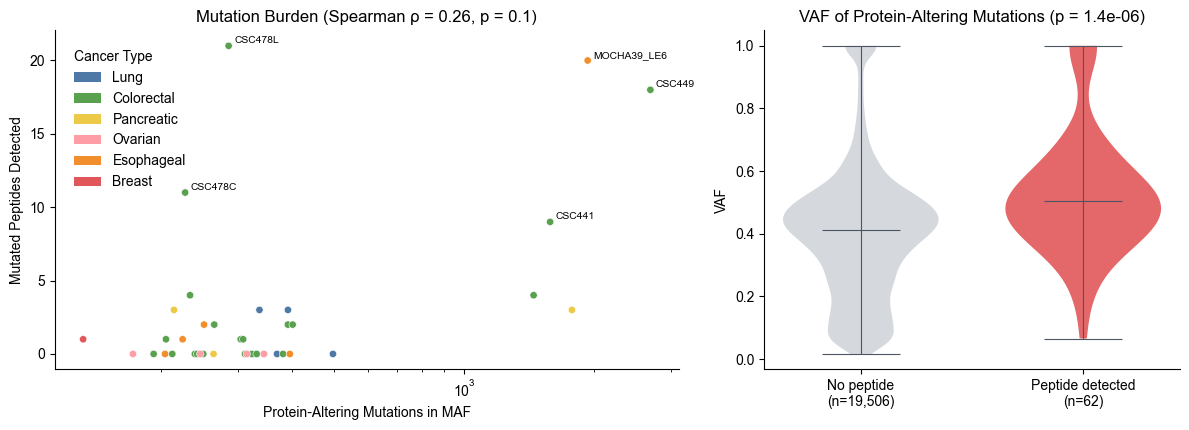

19,568 protein-altering mutations in 40 searched samples; 62 (0.32%) gave a detected mutated peptide


In [19]:
burden = fp_samples.dropna(subset=["maf_barcode"]).copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.2, 0.8]})
ax = axes[0]
ax.scatter(burden["maf_protein_altering"], burden["Mutated"], s=28, color=[CANCER_COLORS.get(o, NOT_RECORDED) for o in burden["cancer_type"]], edgecolor="white", linewidth=0.4)
for _, row in burden.loc[burden["Mutated"].ge(5)].iterrows():
    ax.annotate(row["sample_name"], (row["maf_protein_altering"], row["Mutated"]), xytext=(4, 2), textcoords="offset points", fontsize=7.5)
r, p = stats.spearmanr(burden["maf_protein_altering"], burden["Mutated"])
ax.set_xscale("log")
ax.set_xlabel("Protein-Altering Mutations in MAF")
ax.set_ylabel("Mutated Peptides Detected")
ax.set_title(f"Mutation Burden (Spearman ρ = {r:.2f}, p = {p:.2g})")
left_legend(ax, [Patch(facecolor=CANCER_COLORS[o], label=o) for o in cancer_order if o in set(burden["cancer_type"])], "Cancer Type", (0.01, 0.98))

ax = axes[1]
searched_calls = altering.loc[altering["barcode"].isin(searched_barcodes)].copy()
detected_keys = set(zip(source["maf_barcode"], source["mutation"]))
searched_calls["peptide_detected"] = [(b, m) in detected_keys for b, m in zip(searched_calls["barcode"], searched_calls["mutation"])]
groups = [searched_calls.loc[~searched_calls["peptide_detected"], "vaf"].dropna(), searched_calls.loc[searched_calls["peptide_detected"], "vaf"].dropna()]
parts = ax.violinplot(groups, positions=[0, 1], showmedians=True, widths=0.7)
for body, color in zip(parts["bodies"], [LIGHT_BAR_COLOR, CLASS_COLORS["Mutated"]]):
    body.set_facecolor(color)
    body.set_alpha(0.9)
for key in ["cmedians", "cmins", "cmaxes", "cbars"]:
    parts[key].set_color("#4b5563")
    parts[key].set_linewidth(0.8)
u, p = stats.mannwhitneyu(groups[0], groups[1])
ax.set_xticks([0, 1])
ax.set_xticklabels([f"No peptide\n(n={len(groups[0]):,})", f"Peptide detected\n(n={len(groups[1])})"])
ax.set_ylabel("VAF")
ax.set_title(f"VAF of Protein-Altering Mutations (p = {p:.2g})")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, OUT_DIR / "mutation_burden_vs_mutated_peptides.png")
plt.show()
print(f"{len(searched_calls):,} protein-altering mutations in {searched_calls['barcode'].nunique()} searched samples; "
      f"{searched_calls['peptide_detected'].sum()} ({searched_calls['peptide_detected'].mean():.2%}) gave a detected mutated peptide")

**Driver mutations present in each sample.** Every protein-altering mutation in `DRIVER_GENES` called in the searched samples. Rows are grouped by gene in `DRIVER_GENES` order and, within a gene, ordered by how many searched samples carry the mutation. An open circle means the mutation is called in the sample; a filled red circle means a peptide carrying the mutation was also detected. Driver mutations rarely give detectable HLA ligands. That needs the mutated stretch to be processed into a peptide that binds one of the sample's HLA alleles, so most drivers have no peptide in any given sample.

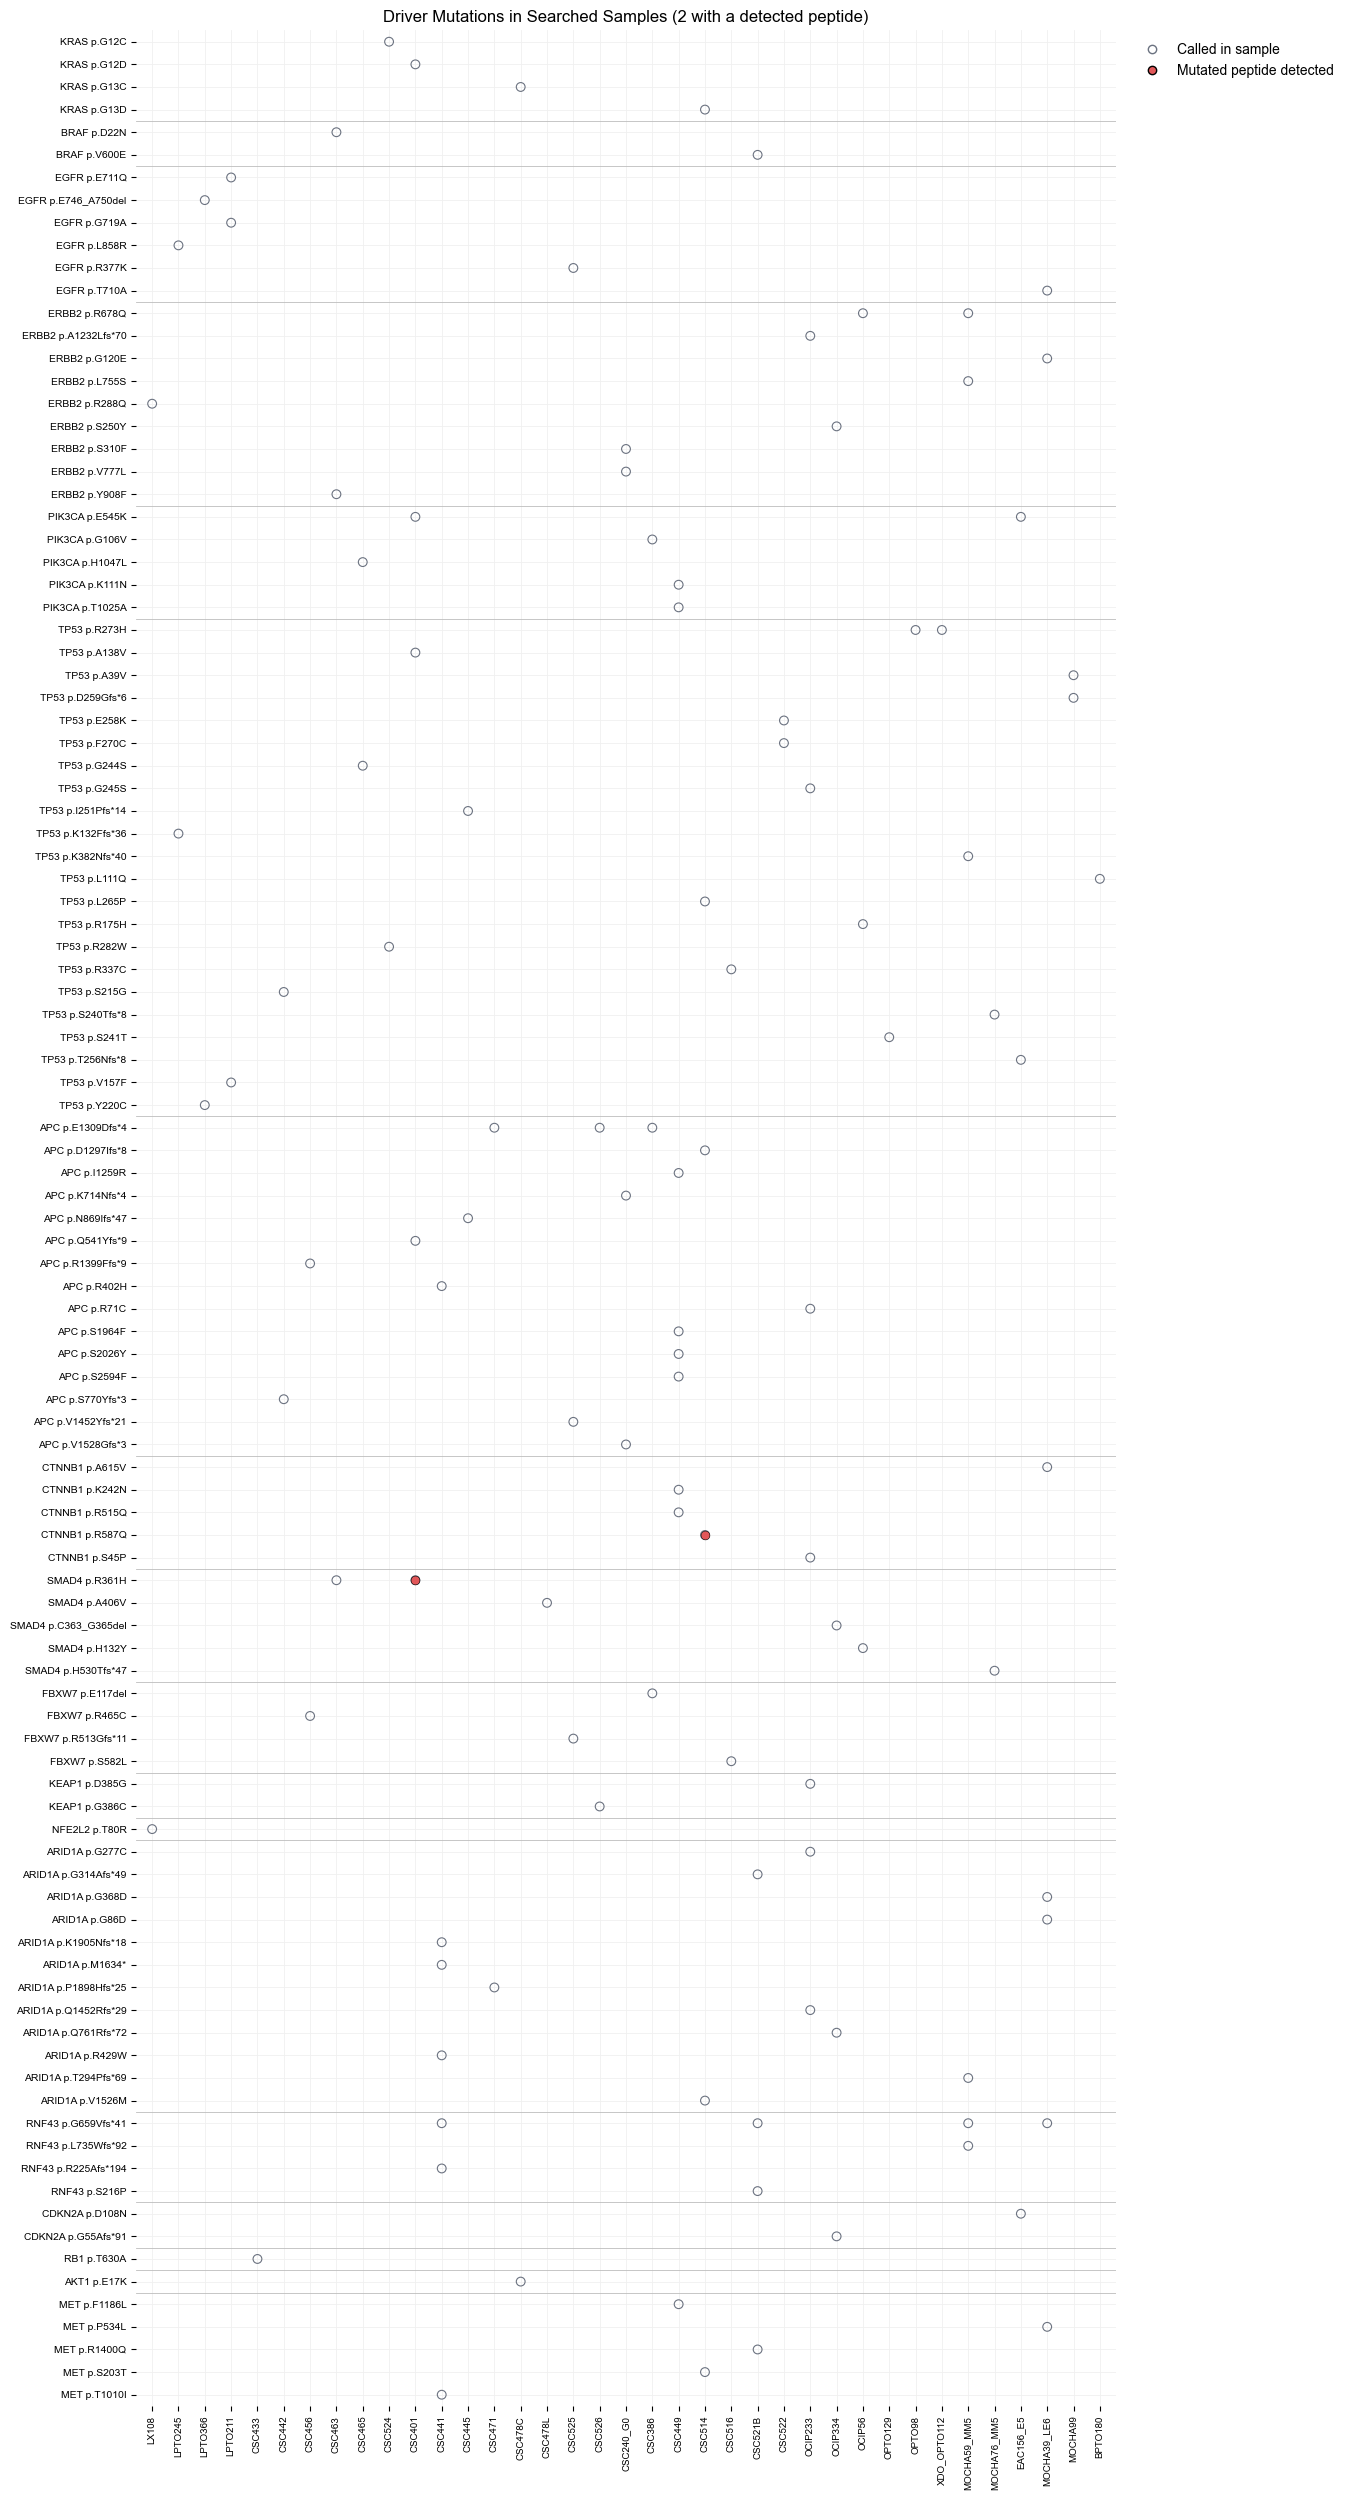

,samples,mutations,detected
gene,,,
KRAS,4,4,0
BRAF,2,2,0
EGFR,5,6,0
ERBB2,8,9,0
PIK3CA,5,5,0
TP53,21,22,0
APC,13,15,0
CTNNB1,4,5,1
SMAD4,6,5,1


In [20]:
drivers = altering.loc[altering["gene"].isin(DRIVER_GENES) & altering["barcode"].isin(searched_barcodes)].copy()
drivers["sample_name"] = drivers["barcode"].map(barcode_to_sample)
drivers["peptide_detected"] = [(b, m) in detected_keys for b, m in zip(drivers["barcode"], drivers["mutation"])]
driver_rank = drivers.groupby("mutation").agg(n=("barcode", "nunique"), gene=("gene", "first"))
driver_rank["gene_rank"] = driver_rank["gene"].map({g: i for i, g in enumerate(DRIVER_GENES)})
driver_order = driver_rank.sort_values(["gene_rank", "n"], ascending=[True, False]).index.tolist()
driver_columns = [s for s in fp_samples["sample_name"] if s in set(drivers["sample_name"])]
row_of = {m: i for i, m in enumerate(driver_order)}
col_of = {s: j for j, s in enumerate(driver_columns)}

fig, ax = plt.subplots(figsize=(2.5 + 0.3 * len(driver_columns), 0.22 * len(driver_order) + 2))
ax.scatter([col_of[s] for s in drivers["sample_name"]], [row_of[m] for m in drivers["mutation"]], s=40, facecolor="none", edgecolor="#6b7280", linewidth=0.8)
hit = drivers.loc[drivers["peptide_detected"]]
ax.scatter([col_of[s] for s in hit["sample_name"]], [row_of[m] for m in hit["mutation"]], s=40, color=CLASS_COLORS["Mutated"], edgecolor="black", linewidth=0.4, zorder=3)
ax.set_yticks(range(len(driver_order)))
ax.set_yticklabels(driver_order, fontsize=7.5)
ax.set_xticks(range(len(driver_columns)))
ax.set_xticklabels(driver_columns, rotation=90, fontsize=7)
ax.set_xlim(-0.6, len(driver_columns) - 0.4)
ax.set_ylim(len(driver_order) - 0.5, -0.5)
genes_in_order = driver_rank.loc[driver_order, "gene"].tolist()
for i in range(1, len(genes_in_order)):
    if genes_in_order[i] != genes_in_order[i - 1]:
        ax.axhline(i - 0.5, color="#bdbdbd", linewidth=0.6)
ax.grid(color="#f0f0f0", linewidth=0.6)
ax.set_axisbelow(True)
ax.spines[:].set_visible(False)
ax.set_title(f"Driver Mutations in Searched Samples ({hit['mutation'].nunique()} with a detected peptide)")
left_legend(ax, [mpl.lines.Line2D([], [], marker="o", linestyle="", markerfacecolor="none", markeredgecolor="#6b7280", label="Called in sample"),
                 mpl.lines.Line2D([], [], marker="o", linestyle="", color=CLASS_COLORS["Mutated"], markeredgecolor="black", label="Mutated peptide detected")], "", (1.01, 1))
fig.tight_layout()
save_fig(fig, OUT_DIR / "driver_mutations_presented.png")
plt.show()
drivers.to_csv(OUT_DIR / "driver_mutations_presented.csv", index=False)
drivers.groupby("gene").agg(samples=("barcode", "nunique"), mutations=("mutation", "nunique"), detected=("peptide_detected", "sum")).reindex([g for g in DRIVER_GENES if g in set(drivers["gene"])])

### Novel ORF peptides

Novel ORF annotations come from the `NOV_` headers: ORF completeness (`complete`, `5prime_partial`, `3prime_partial`, `internal`), strand, and StringTie locus.

**Nearest canonical sequence.** A novel ORF peptide one substitution away from a canonical protein is more likely a germline variant (or RNA editing) in a known protein, picked up because the StringTie transcripts were assembled from that patient's RNA. Peptides with no canonical match within one substitution are the strongest novel ORF candidates.

In [21]:
novel = fp.loc[fp["class"].eq("Novel ORF")].copy()
novel["nov_ids"] = novel["accessions"].map(lambda a: accession_ids(a, "NOV_"))
novel_orfs = novel[["peptide", "nov_ids"]].explode("nov_ids").join(nov_info, on="nov_ids")
novel_orf_summary = novel_orfs.groupby("peptide").agg(
    orf_type=("orf_type", lambda s: ";".join(sorted(set(s.dropna())))),
    strand=("strand", lambda s: ";".join(sorted(set(s.dropna())))),
    loci=("locus", lambda s: ";".join(sorted(set(s.dropna())))),
    n_orfs=("nov_ids", "nunique"),
)
nearest_novel = {p: proteome.nearest(p) for p in novel["peptide"].unique()}
novel_peptides = novel.groupby("peptide").agg(
    length=("length", "first"), n_samples=("alias", "nunique"), samples=("sample_name", lambda s: ";".join(sorted(s))),
    total_spectral_count=("spectral_count", "sum"), max_probability=("probability", "max"),
).join(novel_orf_summary)
novel_peptides["nearest_canonical"] = novel_peptides.index.map(lambda p: nearest_novel[p][0])
novel_peptides["nearest_detail"] = novel_peptides.index.map(lambda p: nearest_novel[p][1])
novel["denovo_best_score"] = [denovo_support(a, p) for a, p in zip(novel["alias"], novel["peptide"])]
novel_peptides["denovo_best_score"] = novel.groupby("peptide")["denovo_best_score"].max()
novel_peptides = novel_peptides.sort_values(["n_samples", "total_spectral_count"], ascending=False)
novel_peptides.to_csv(OUT_DIR / "novel_orf_peptides.csv")
print(f"{len(novel_peptides):,} unique novel ORF peptides")
print("nearest canonical:", novel_peptides["nearest_canonical"].value_counts().to_dict())
novel_peptides.head(20)

1,255 unique novel ORF peptides
nearest canonical: {'none': 953, '1 substitution': 302}


,length,n_samples,samples,total_spectral_count,max_probability,orf_type,strand,loci,n_orfs,nearest_canonical,nearest_detail,denovo_best_score
peptide,,,,,,,,,,,,
RMAEPMKGY,9,9,BPTO180;CSC465;CSC516;CSC526;EAC156_E5;EAC52;O...,22,1.0000,complete,+,STRG.5387;STRG.5398;STRG.5606;STRG.5727;STRG.5...,21,none,,0.900808
MPLRGGLSV,9,9,BPTO180;CSC401;CSC465;CSC478C;CSC526;DCBPTO19;...,20,0.9997,complete,+,STRG.21047;STRG.4897;STRG.5118;STRG.5394;STRG....,27,none,,0.897911
SSGGSYRDSYDSYG,14,9,CSC386;CSC401;CSC445;CSC449;CSC521B;LPTO211;LP...,9,1.0000,complete,+,STRG.23194;STRG.24016;STRG.25663;STRG.26257;ST...,19,1 substitution,CIRBP A168G (peptide pos 14),0.879241
HPTADVQTF,9,7,EAC156_E5;EAC52;LPTO211;LPTO245;LPTO251;OPTO98...,12,0.9998,complete,+,STRG.211;STRG.236;STRG.271;STRG.274;STRG.289;S...,11,none,,0.755102
TPAPRGPLL,9,7,CSC442;CSC471;CSC478C;CSC478L;DCBPTO19;EAC52;O...,10,0.9973,3prime_partial;complete,-,STRG.20217;STRG.21136;STRG.21429;STRG.21735;ST...,24,1 substitution,CDRT15 N161P (peptide pos 7),NaN
TYLSIIHSL,9,6,CSC445;CSC526;DCBPTO19;EAC46;EAC52;LX108,13,0.9999,complete,+,STRG.23693;STRG.23820;STRG.25016;STRG.28617;ST...,14,1 substitution,NUP88 P287L (peptide pos 9),0.908134
VILPPQPPK,9,5,BPTO180;EAC156_E5;LPTO251;LPTO366;XDO_OPTO112,25,0.9988,5prime_partial;complete,+;-,STRG.10615;STRG.14389;STRG.18824;STRG.21977;ST...,7,1 substitution,MYL10 R18Q (peptide pos 6),0.903994
ASCSPGRPL,9,5,CSC471;CSC521B;CSC526;LPTO251;LX108,15,0.9976,complete,+,STRG.11900;STRG.2525;STRG.2555;STRG.3005;STRG....,10,none,,NaN
ALVSGLHGV,9,5,CSC471;CSC516;LPTO147;MOCHA39_LE6;OCIP56,10,0.9998,5prime_partial;complete,+,STRG.22165;STRG.22178;STRG.24632;STRG.26752;ST...,5,none,,0.912459


- **Left:** novel ORF peptides by the completeness of their ORF. A peptide mapping to several ORFs is counted under each of its ORF types (joined with `;`).
- **Middle:** distance to the nearest canonical sequence.
- **Right:** novel ORF peptides per sample, split by distance to canonical.

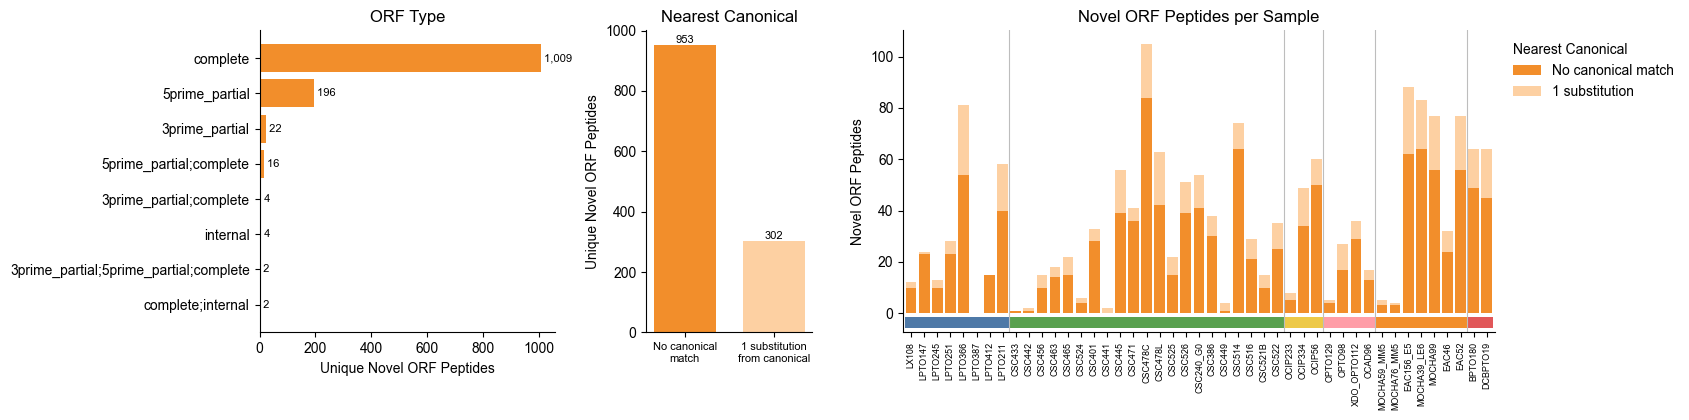

In [22]:
NEAREST_COLORS = {"none": "#f28e2b", "1 substitution": "#fdd0a2"}
novel["nearest_canonical"] = novel["peptide"].map(novel_peptides["nearest_canonical"])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw={"width_ratios": [0.8, 0.45, 1.6]})
ax = axes[0]
orf_counts = novel_peptides["orf_type"].value_counts()
ax.barh(orf_counts.index[::-1], orf_counts.values[::-1], color=CLASS_COLORS["Novel ORF"])
for i, v in enumerate(orf_counts.values[::-1]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
ax.set_xlabel("Unique Novel ORF Peptides")
ax.set_title("ORF Type")
ax = axes[1]
near_counts = novel_peptides["nearest_canonical"].value_counts().reindex(NEAREST_COLORS).fillna(0)
ax.bar(range(len(near_counts)), near_counts.values, color=list(NEAREST_COLORS.values()), width=0.7)
for i, v in enumerate(near_counts.values):
    ax.text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(range(len(near_counts)))
ax.set_xticklabels(["No canonical\nmatch", "1 substitution\nfrom canonical"], fontsize=8)
ax.set_ylabel("Unique Novel ORF Peptides")
ax.set_title("Nearest Canonical")
ax = axes[2]
near_by_sample = novel.groupby(["nearest_canonical", "alias"]).size().unstack(fill_value=0).reindex(index=list(NEAREST_COLORS), columns=fp_samples["alias"]).fillna(0)
x = np.arange(len(fp_samples))
stacked_bars(ax, near_by_sample, NEAREST_COLORS, x=x)
ax.set_ylabel("Novel ORF Peptides")
ax.set_title("Novel ORF Peptides per Sample")
bottom_strip(ax, fp_samples["cancer_type"], CANCER_COLORS)
group_dividers(ax, fp_samples["cancer_type"])
ax.set_xticks(x)
ax.set_xticklabels(fp_samples["sample_name"], rotation=90, fontsize=6.5)
ax.set_xlim(-0.6, len(fp_samples) - 0.4)
left_legend(ax, [Patch(facecolor=NEAREST_COLORS["none"], label="No canonical match"), Patch(facecolor=NEAREST_COLORS["1 substitution"], label="1 substitution")], "Nearest Canonical", (1.01, 1))
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, OUT_DIR / "novel_orf_peptides.png")
plt.show()

## 5. De Novo Sequencing vs Database Search

For the samples with both results, peptides are compared within each run, with I and L treated as the same residue.

- **Recall:** the percentage of FragPipe peptides (1% FDR) that Casanovo also sequenced confidently.
- **Database-explained de novo:** the percentage of confident de novo peptides that FragPipe also identified in that run.

Agreement is expected to be partial. The two tools often pick different spectra for the same peptide, and Casanovo's errors on HLA ligands are often partial: the right composition with two residues swapped, or a near-isobaric substitution such as GG for N.

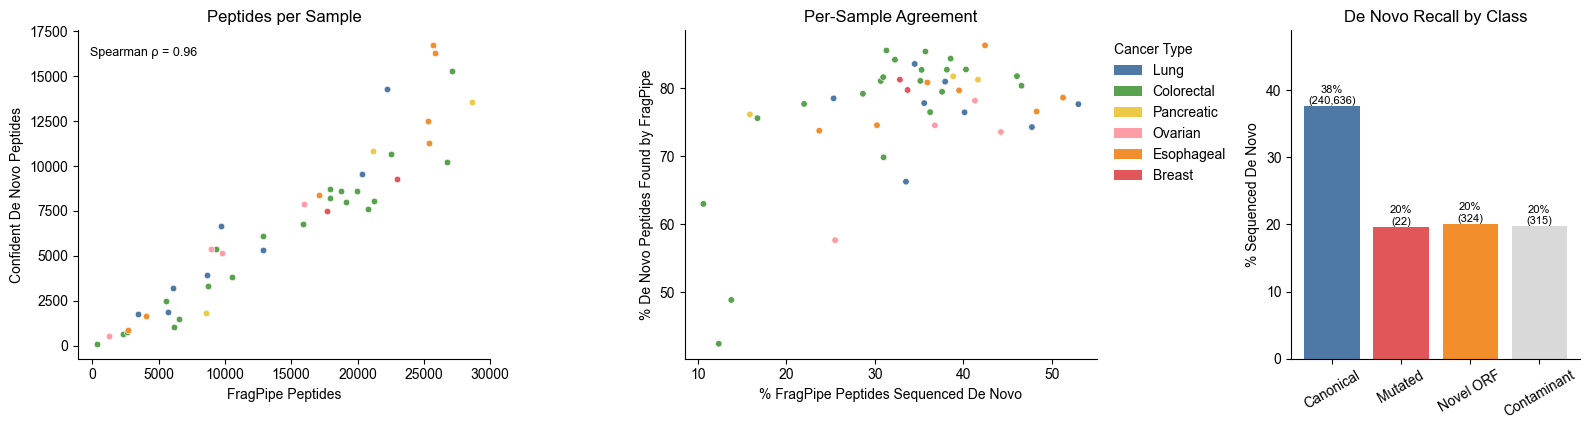

,fragpipe,denovo,shared,recall_pct,denovo_explained_pct
count,45.0,45.0,45.0,45.0,45.0
mean,14288.7,6710.7,5362.2,34.2,76.8
std,8381.2,4571.1,3686.7,10.0,8.9
min,340.0,99.0,42.0,10.6,42.4
25%,6558.0,2467.0,1723.0,30.7,75.6
50%,15872.0,6768.0,5598.0,35.6,79.2
75%,21133.0,9284.0,7545.0,40.1,81.6
max,28611.0,16728.0,13152.0,53.0,86.3


In [23]:
denovo_sets = denovo.groupby("alias", observed=True)["peptide_il"].agg(lambda s: set(s.astype(str)))
fp_sets = fp.assign(peptide_il=fp["peptide"].map(fold_il)).groupby("alias")["peptide_il"].agg(set)
agreement = []
for alias in fp_samples["alias"]:
    dn, db = denovo_sets.get(alias, set()), fp_sets[alias]
    shared = dn & db
    agreement.append({"alias": alias, "fragpipe": len(db), "denovo": len(dn), "shared": len(shared),
                      "recall_pct": len(shared) / len(db) * 100, "denovo_explained_pct": len(shared) / max(len(dn), 1) * 100})
agreement = pd.DataFrame(agreement).merge(fp_samples[["alias", "sample_name", "cancer_type"]], on="alias")

# recall by class, pooled over samples
fp_il = fp.assign(peptide_il=fp["peptide"].map(fold_il))
fp_il["denovo_confident"] = [p in denovo_sets.get(a, set()) for a, p in zip(fp_il["alias"], fp_il["peptide_il"])]
recall_by_class = fp_il.groupby("class")["denovo_confident"].agg(["mean", "sum", "size"]).reindex(CLASS_ORDER)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1, 1, 0.7]})
ax = axes[0]
for cancer, sub in agreement.groupby("cancer_type"):
    ax.scatter(sub["fragpipe"], sub["denovo"], s=22, color=CANCER_COLORS.get(cancer, NOT_RECORDED), edgecolor="white", linewidth=0.4, label=cancer)
r, p = stats.spearmanr(agreement["fragpipe"], agreement["denovo"])
ax.text(0.03, 0.95, f"Spearman ρ = {r:.2f}", transform=ax.transAxes, va="top", fontsize=9)
ax.set_xlabel("FragPipe Peptides")
ax.set_ylabel("Confident De Novo Peptides")
ax.set_title("Peptides per Sample")
ax = axes[1]
order = agreement.sort_values("recall_pct").reset_index(drop=True)
ax.scatter(order["recall_pct"], order["denovo_explained_pct"], s=22, color=[CANCER_COLORS.get(o, NOT_RECORDED) for o in order["cancer_type"]], edgecolor="white", linewidth=0.4)
ax.set_xlabel("% FragPipe Peptides Sequenced De Novo")
ax.set_ylabel("% De Novo Peptides Found by FragPipe")
ax.set_title("Per-Sample Agreement")
ax = axes[2]
ax.bar(range(len(recall_by_class)), recall_by_class["mean"] * 100, color=[CLASS_COLORS[c] for c in recall_by_class.index])
for i, (m, s) in enumerate(zip(recall_by_class["mean"], recall_by_class["sum"])):
    ax.text(i, m * 100, f"{m * 100:.0f}%\n({int(s):,})", ha="center", va="bottom", fontsize=8)
ax.set_xticks(range(len(recall_by_class)))
ax.set_xticklabels(recall_by_class.index, rotation=30)
ax.set_ylabel("% Sequenced De Novo")
ax.set_ylim(0, recall_by_class["mean"].max() * 130)
ax.set_title("De Novo Recall by Class")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
left_legend(axes[1], [Patch(facecolor=CANCER_COLORS[o], label=o) for o in cancer_order if o in set(agreement["cancer_type"])], "Cancer Type", (1.01, 1))
fig.tight_layout()
save_fig(fig, OUT_DIR / "denovo_vs_fragpipe.png")
plt.show()
agreement.to_csv(OUT_DIR / "denovo_vs_fragpipe_agreement.csv", index=False)
agreement[["fragpipe", "denovo", "shared", "recall_pct", "denovo_explained_pct"]].describe().round(1)

## 6. Peptide Yield and Sample Properties

Confident de novo peptides per run (all 171 runs) against sample metadata. De novo counts are used here because they exist for every run and track the FragPipe counts (Section 5). Points are runs; lines are medians.

The right panel shows the input cell number, where recorded. Spearman ρ is given in the title.

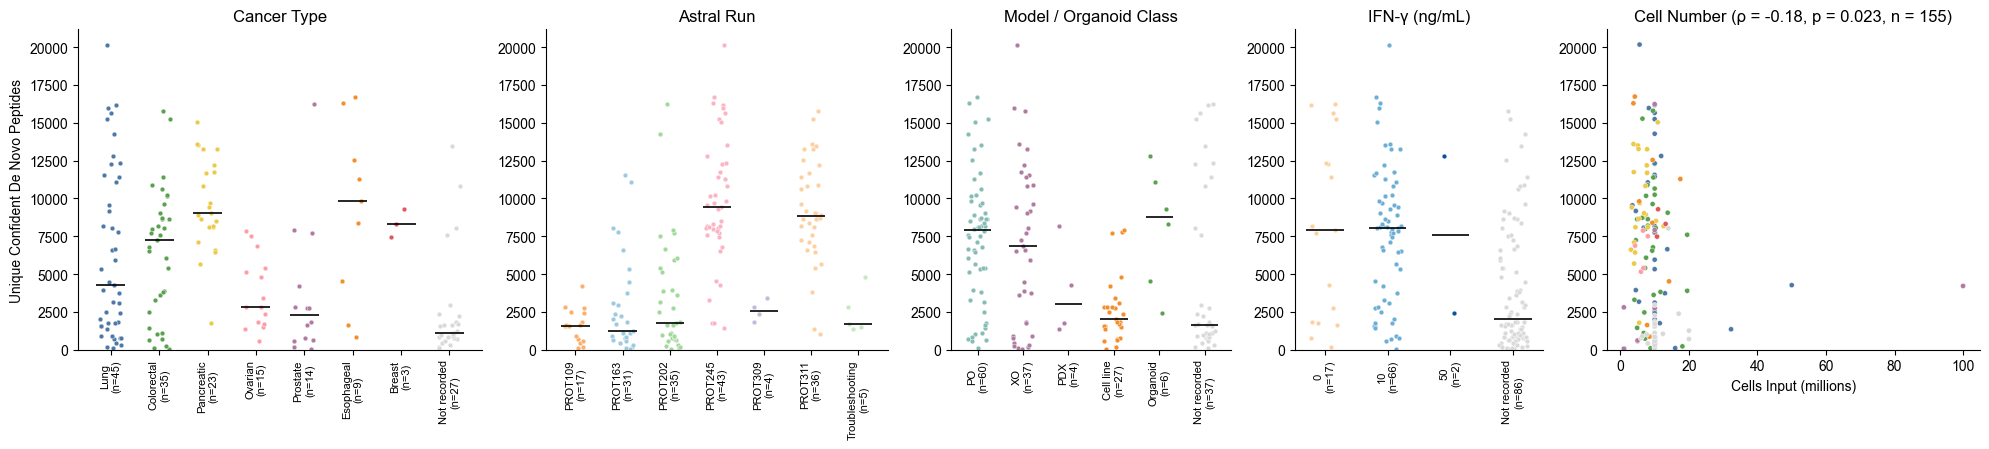

In [24]:
def strip_by_group(ax, data, group_col, value_col, order, palette, title):
    for i, group in enumerate(order):
        values = data.loc[data[group_col].eq(group), value_col].dropna()
        jitter = np.random.default_rng(0).uniform(-0.22, 0.22, len(values))
        ax.scatter(np.full(len(values), i) + jitter, values, s=12, color=palette.get(group, NOT_RECORDED), edgecolor="white", linewidth=0.3)
        if len(values):
            ax.hlines(values.median(), i - 0.3, i + 0.3, color="black", linewidth=1.2)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"{g}\n(n={data[group_col].eq(g).sum()})" for g in order], rotation=90, fontsize=8)
    ax.set_title(title)


samples["cell_number_M"] = pd.to_numeric(samples["cell_number_M"], errors="coerce")
samples["model_class"] = np.where(samples["sample_class"].ne("Not recorded"), samples["sample_class"], samples["model"])
model_order = [m for m in ["PO", "XO", "PDX", "Cell line", "Organoid", "Not recorded"] if m in set(samples["model_class"])]
ifng_order = [v for v in ["0", "10", "50", "Not recorded"] if v in set(samples["ifng"])]

fig, axes = plt.subplots(1, 5, figsize=(20, 4.6), gridspec_kw={"width_ratios": [1.3, 1.1, 0.9, 0.8, 1.2]})
value = "confident_peptides"
strip_by_group(axes[0], samples, "cancer_type", value, cancer_order, CANCER_COLORS, "Cancer Type")
strip_by_group(axes[1], samples, "ms_run", value, run_order, PALETTES["ms_run"], "Astral Run")
strip_by_group(axes[2], samples, "model_class", value, model_order, {**PALETTES["sample_class"], **PALETTES["model"]}, "Model / Organoid Class")
strip_by_group(axes[3], samples, "ifng", value, ifng_order, PALETTES["ifng"], "IFN-γ (ng/mL)")
ax = axes[4]
has_cells = samples.dropna(subset=["cell_number_M"])
ax.scatter(has_cells["cell_number_M"], has_cells[value], s=14, color=[CANCER_COLORS.get(o, NOT_RECORDED) for o in has_cells["cancer_type"]], edgecolor="white", linewidth=0.3)
r, p = stats.spearmanr(has_cells["cell_number_M"], has_cells[value])
ax.set_xlabel("Cells Input (millions)")
ax.set_title(f"Cell Number (ρ = {r:.2f}, p = {p:.2g}, n = {len(has_cells)})")
axes[0].set_ylabel("Unique Confident De Novo Peptides")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(bottom=0)
fig.tight_layout()
save_fig(fig, OUT_DIR / "peptide_yield_vs_metadata.png")
plt.show()

**Sample similarity.** Jaccard index of the FragPipe canonical peptide sets, ordered by hierarchical clustering. Samples from the same patient or model (for example, `CSC478C`/`CSC478L` and `OPTO98`/`XDO_OPTO112`) and samples sharing HLA alleles share more peptides. High overlap between unrelated samples from different cancer types (for example, the `CSC514` / `EAC46` / `CSC471` / `MOCHA99` block) is most likely shared HLA alleles; this can be checked against the arcasHLA typing in `data/rna/hla_summary.csv`. The strip on top is the cancer type.

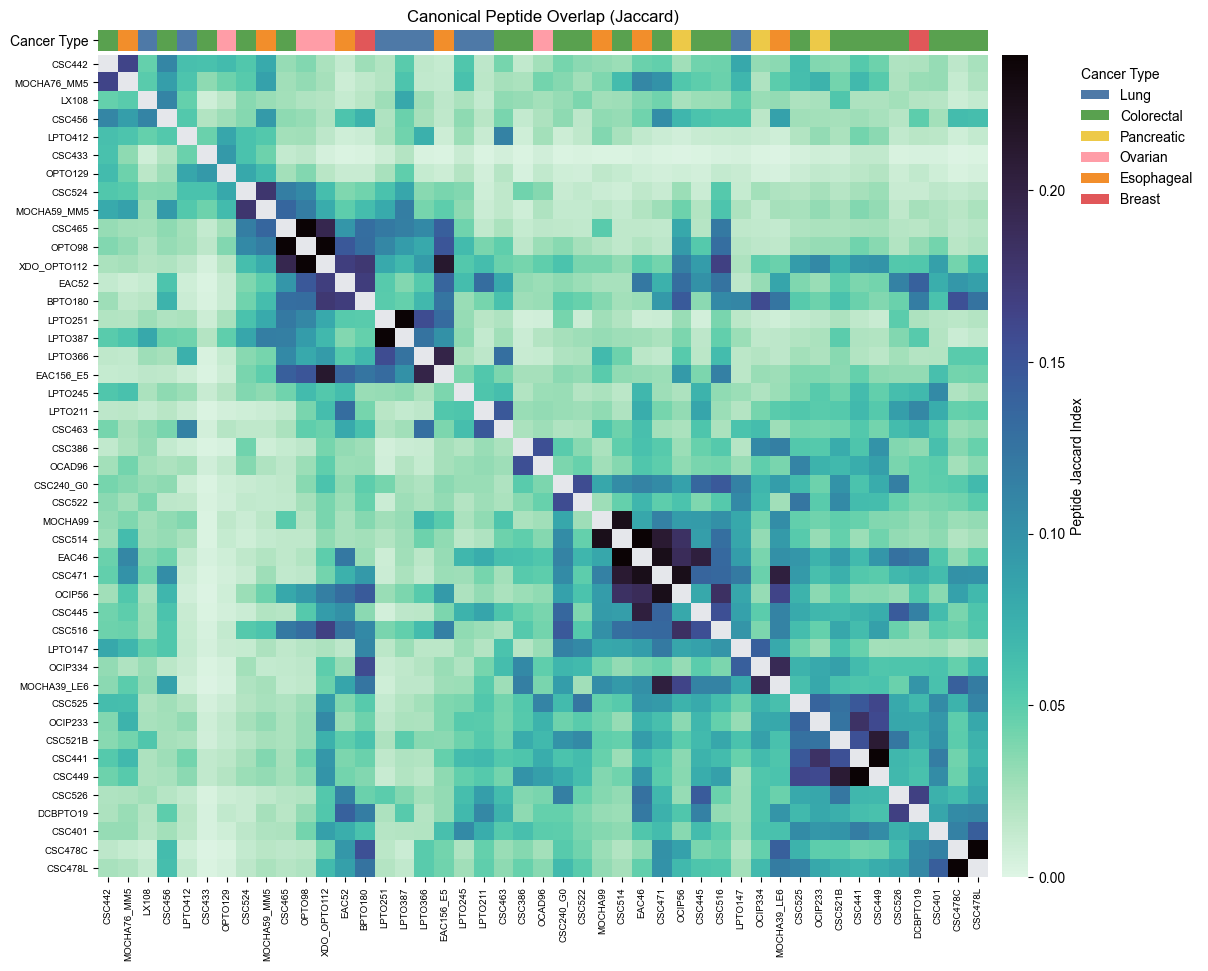

jaccard
sample_name sample_name          
CSC478C     CSC478L      0.414187
OPTO98      XDO_OPTO112  0.328591
CSC465      OPTO98       0.249031
CSC514      EAC46        0.241581
CSC441      CSC449       0.240853
LPTO251     LPTO387      0.239216
CSC471      OCIP56       0.226050
            EAC46        0.225523
CSC514      MOCHA99      0.225138
XDO_OPTO112 EAC156_E5    0.212517

In [25]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

canonical_sets = fp.loc[fp["class"].eq("Canonical")].groupby("alias")["peptide"].agg(set).reindex(fp_samples["alias"])
peptide_index = {p: i for i, p in enumerate(sorted(set().union(*canonical_sets)))}
presence = np.zeros((len(canonical_sets), len(peptide_index)), dtype=np.float32)
for i, peptide_set in enumerate(canonical_sets):
    presence[i, [peptide_index[p] for p in peptide_set]] = 1
intersection = presence @ presence.T
sizes = np.diag(intersection)
jaccard = intersection / (sizes[:, None] + sizes[None, :] - intersection)
order = leaves_list(linkage(squareform(1 - jaccard, checks=False), method="average"))
jac = jaccard[np.ix_(order, order)].copy()
names = fp_samples["sample_name"].values[order]
cancer_types = fp_samples["cancer_type"].values[order]

fig = plt.figure(figsize=(12, 11))
grid = fig.add_gridspec(nrows=2, ncols=2, width_ratios=[1, 0.03], height_ratios=[0.025, 1], hspace=0.01, wspace=0.03)
ax_org = fig.add_subplot(grid[0, 0])
ax_heat = fig.add_subplot(grid[1, 0], sharex=ax_org)
cax = fig.add_subplot(grid[1, 1])
ax_org.imshow(np.array([mpl.colors.to_rgba(CANCER_COLORS.get(o, NOT_RECORDED)) for o in cancer_types])[None, :, :], aspect="auto")
ax_org.set_yticks([0])
ax_org.set_yticklabels(["Cancer Type"])
ax_org.tick_params(axis="x", bottom=False, labelbottom=False)
ax_org.spines[:].set_visible(False)
ax_org.set_title("Canonical Peptide Overlap (Jaccard)")
np.fill_diagonal(jac, np.nan)
cmap = mpl.colormaps["mako_r"].copy()
cmap.set_bad("#e5e7eb")
im = ax_heat.imshow(np.ma.masked_invalid(jac), cmap=cmap, vmin=0, vmax=np.nanpercentile(jac, 99.5), aspect="auto")
ax_heat.set_xticks(range(len(names)))
ax_heat.set_xticklabels(names, rotation=90, fontsize=7)
ax_heat.set_yticks(range(len(names)))
ax_heat.set_yticklabels(names, fontsize=7)
ax_heat.spines[:].set_visible(False)
cbar = fig.colorbar(im, cax=cax)
cbar.outline.set_visible(False)
cbar.set_label("Peptide Jaccard Index")
left_legend(cax, [Patch(facecolor=CANCER_COLORS[o], label=o) for o in cancer_order if o in set(cancer_types)], "Cancer Type", (2.5, 1))
save_fig(fig, OUT_DIR / "fragpipe_sample_similarity.png")
plt.show()

pairs = pd.DataFrame(jaccard, index=fp_samples["sample_name"], columns=fp_samples["sample_name"]).where(np.triu(np.ones_like(jaccard, dtype=bool), 1)).stack()
pairs.sort_values(ascending=False).head(10).rename("jaccard").to_frame()

**Source genes.** The genes giving the most canonical peptides across all samples, counted as sample-peptide pairs (FragPipe `Gene`, the gene of the first protein each peptide maps to). The label gives the unique peptides and the number of samples with that gene.

Genes in `SKIN_GENES` (epidermal keratins and dermcidin, sweat) are marked in gray with `*`. Organoids don't express them, so they most likely come from handling (skin/dust) and are not HLA ligands. Their peptides are counted as canonical everywhere else in this notebook.

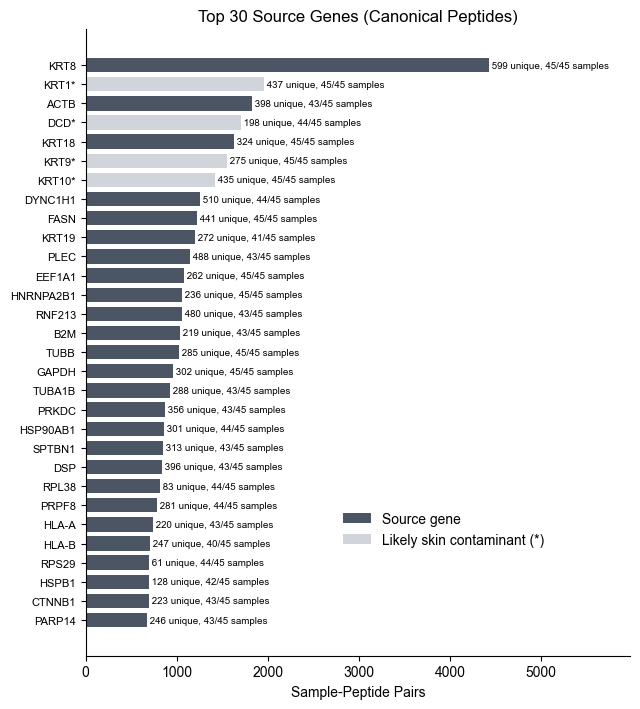

skin-contaminant genes: 1.2% of canonical identifications (per sample median 0.9%, max 41.1% in CSC433)


In [26]:
N_TOP_GENES = 30
SKIN_GENES = ["KRT1", "KRT2", "KRT5", "KRT9", "KRT10", "KRT14", "DCD"]
canonical = fp.loc[fp["class"].eq("Canonical")]
gene_counts = canonical.groupby("gene").agg(pairs=("peptide", "size"), unique_peptides=("peptide", "nunique"), n_samples=("alias", "nunique")).sort_values("pairs", ascending=False)
top_genes = gene_counts.head(N_TOP_GENES)
fig, ax = plt.subplots(figsize=(6.5, 0.2 * N_TOP_GENES + 1.2))
is_skin = top_genes.index.isin(SKIN_GENES)
ax.barh(range(len(top_genes)), top_genes["pairs"], color=np.where(is_skin, LIGHT_BAR_COLOR, BAR_COLOR), height=0.75)
for i, (v, u, n) in enumerate(zip(top_genes["pairs"], top_genes["unique_peptides"], top_genes["n_samples"])):
    ax.text(v, i, f" {u} unique, {n}/{len(fp_samples)} samples", va="center", fontsize=7)
ax.set_yticks(range(len(top_genes)))
ax.set_yticklabels([f"{g}*" if s else g for g, s in zip(top_genes.index, is_skin)], fontsize=8)
ax.set_xlim(0, top_genes["pairs"].max() * 1.35)
ax.invert_yaxis()
ax.set_xlabel("Sample-Peptide Pairs")
ax.set_title(f"Top {N_TOP_GENES} Source Genes (Canonical Peptides)")
ax.spines[["top", "right"]].set_visible(False)
left_legend(ax, [Patch(facecolor=BAR_COLOR, label="Source gene"), Patch(facecolor=LIGHT_BAR_COLOR, label="Likely skin contaminant (*)")], "", (0.45, 0.25))
fig.tight_layout()
save_fig(fig, OUT_DIR / "top_source_genes.png")
plt.show()
gene_counts.assign(skin_contaminant=gene_counts.index.isin(SKIN_GENES)).to_csv(OUT_DIR / "canonical_source_genes.csv")
skin = canonical["gene"].isin(SKIN_GENES).groupby(canonical["sample_name"]).mean().mul(100)
print(f"skin-contaminant genes: {canonical['gene'].isin(SKIN_GENES).mean():.1%} of canonical identifications "
      f"(per sample median {skin.median():.1f}%, max {skin.max():.1f}% in {skin.idxmax()})")

## Summary Table

One row per MS run with its metadata and peptide counts, written to `sample_peptide_summary.csv`.

In [27]:
summary = samples.merge(
    fp_samples[["alias", "fragpipe_peptides", "fragpipe_proteins", "fragpipe_psms"] + CLASS_ORDER], on="alias", how="left"
).merge(agreement[["alias", "recall_pct", "denovo_explained_pct"]], on="alias", how="left")
summary_cols = ["sample_name", "alias", "ms_run", "cancer_type", "oncotree", "model", "sample_class", "ifng", "cell_number_M",
                "spectra", "confident_psms", "confident_peptides", "pct_in_proteome", "pct_hla_i_length",
                "fragpipe_peptides", "fragpipe_proteins", "fragpipe_psms"] + CLASS_ORDER + ["recall_pct", "denovo_explained_pct"]
summary[summary_cols].to_csv(OUT_DIR / "sample_peptide_summary.csv", index=False)
summary.loc[summary["has_fragpipe"], summary_cols].round(1).set_index("sample_name")

,alias,ms_run,cancer_type,oncotree,model,sample_class,ifng,cell_number_M,spectra,confident_psms,...,pct_hla_i_length,fragpipe_peptides,fragpipe_proteins,fragpipe_psms,Canonical,Mutated,Novel ORF,Contaminant,recall_pct,denovo_explained_pct
sample_name,,,,,,,,,,,,,,,,,,,,,
LX108,PROT109_He_LX108,PROT109,Lung,SCLC,Organoid,XO,Not recorded,10.0,42659,2808,...,93.6,5729.0,3527.0,10041.0,5706.0,0.0,12.0,11.0,25.3,78.5
LPTO147,PROT163_He_LPTO147,PROT163,Lung,"SCLC, LUNE",Organoid,PO,10,10.0,76386,7290,...,94.8,12902.0,5699.0,19840.0,12859.0,0.0,24.0,19.0,34.5,83.6
LPTO245,PROT202_He_LPTO_245,PROT202,Lung,LUAD,Organoid,PO,Not recorded,4.5,41735,5507,...,89.8,8624.0,4251.0,13407.0,8583.0,3.0,13.0,25.0,35.6,77.8
LPTO251,PROT202_He_LPTO_251,PROT202,Lung,LUPC,Organoid,PO,Not recorded,13.7,41008,9382,...,94.9,9733.0,4612.0,14935.0,9696.0,0.0,28.0,9.0,53.0,77.7
LPTO366,PROT202_He_LPTO_366,PROT202,Lung,LUAD,Organoid,PO,Not recorded,10.0,87198,20512,...,92.3,22215.0,7210.0,35185.0,22113.0,0.0,81.0,21.0,47.7,74.3
LPTO387,PROT202_He_LPTO_387,PROT202,Lung,LUAD,Organoid,PO,Not recorded,5.4,35307,4348,...,94.2,6056.0,3379.0,8933.0,6047.0,0.0,0.0,9.0,40.1,76.5
LPTO412,PROT202_He_LTPO_412,PROT202,Lung,LUAD,Organoid,PO,10,10.0,32760,2221,...,92.0,3447.0,1985.0,5219.0,3422.0,0.0,15.0,10.0,33.5,66.3
LPTO211,51126_PROT245_He_LPTO_211,PROT245,Lung,"LUAD, NSCLC",Organoid,PO,10,3.5,81187,14945,...,83.9,20372.0,6807.0,33443.0,20264.0,3.0,58.0,47.0,37.9,81.0
CSC433,PROT202_He_CSC_433,PROT202,Colorectal,COAD,Organoid,PO,Not recorded,8.8,29477,123,...,70.7,340.0,170.0,434.0,331.0,0.0,1.0,8.0,12.4,42.4
